In [56]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_cost_function_with_minima, 
    plot_ploidy_optimization,
    plot_ploidy_comparison,  # Add this
    print_overlap_matrix, 
    plot_overlap_matrix_figure,
    plot_uniformity_histograms_nice
)
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

import time

In [57]:
numb = "24"
tumor = "t"+numb

In [58]:
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values
#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [59]:
bincounts[bincounts["chrom"]=="chr19"]

,chrom,loc.start,loc.end,abstart,abend,AAAACCAAAATGGATCG,AAAACCAAAGATGTTAG,AAAACCAGCTTAAGAAG,AAAACCAGCTTATTATT,AAAACCAGTTTGCAAGT,...,TGCTGCGACTGGTTACC,TGGCCTCTGTTTACACA,TGGCCTTAACCAAGAGA,TGGCCTTTAAGGACTCT,TGGCCTTTGAGCTGATA,TTTCGAAGAATTGTATG,TTTCGAATCCGGTATCT,TTTCGAGAACCCTTACC,TTTCGAGGTGACAGAAG,TTTTGGTACTCCGATGT
76,chr19,0,9757752,2659444323,2669202075,29,39,65,11,60,...,33,65,1,2,5,18,12,29,3,25
77,chr19,10336520,19628957,2669780843,2679073280,56,78,152,33,93,...,60,91,2,50,3,27,31,17,61,29
78,chr19,20216744,58522984,2679661067,2717967307,196,249,466,198,437,...,148,189,29,12,215,136,122,3,206,192


In [ ]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")
#equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [61]:
A_df.head()

,cell,population,normal_population
0,AAAACCAGCTTAAGAAG,B1111,False
1,AAAACCATAGCATAAGC,B1111,False
2,AAAACCGATGCAGCTAA,B1111,False
3,AAAACCGATGCAGTACA,B1111,False
4,AAAATGAAATCCCTACT,B1111,False


In [62]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }


B1111
B11121
B11122
B112
B12
B2


In [63]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

A11
A12
A2


In [64]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C1111
C1112
C112
C12
C2


In [65]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D1111
D1112
D112
D12
D2


In [66]:
# equi_dict = {}
# for cluster in equi_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = equi_df[equi_df['population'] == cluster]['cell'].tolist()
#     equi_dict[cluster] = {
#         'cells': cells_in_cluster
#     }

In [67]:
#overlap_df = print_overlap_matrix(A_dict, equi_dict, name1="WGS bins - ", name2="equi-partitioned bins -")

In [68]:
# new_order = []
# for col in overlap_df.columns:
#     #Find the index of the maximum value in the column
#     max_index = overlap_df[col].idxmax()
#     if max_index not in new_order:
#         new_order.append(max_index)

# for row in overlap_df.index:
#     if row not in new_order:
#         new_order.append(row)
# new_order_dict = {k: A_dict[k] for k in new_order}
    

In [69]:
cluster_counts = bincounts[["chrom", "abstart", "abend"]].copy()
for cluster in A_dict.keys():
    cells_in_cluster = A_dict[cluster]['cells']
    cluster_counts[cluster] = bincounts[cells_in_cluster].sum(axis=1)

In [70]:
cluster_counts.to_csv(f"../data/{tumor}/{tumor}_cluster_counts_A_WGS_bins.txt", sep="\t", index=False)

In [71]:
#overlap_df = plot_overlap_matrix_figure(A_dict, equi_dict, name1="WGS bins", name2="equi-partitioned bins")


Overlap Matrix (A rows vs B cols):
Pop          A11     A12      A2
B1111        285      49       0
B11121       120      27       0
B11122       238       9       0
B112         533      65       0
B12           23    1053       0
B2             0       0     122


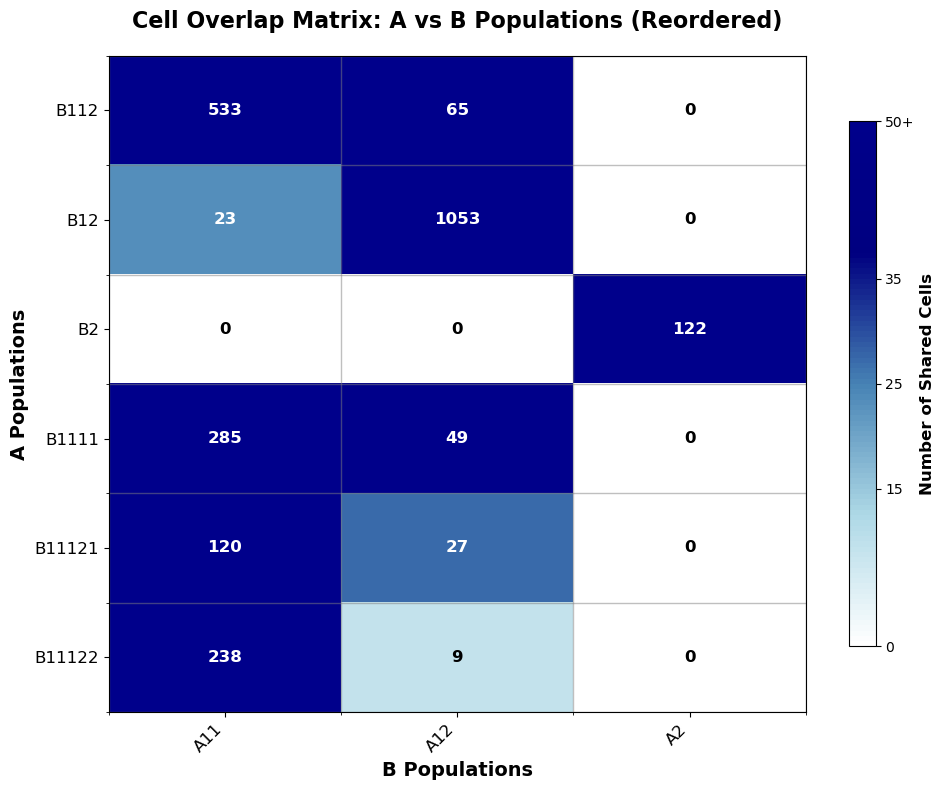

In [72]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")


Overlap Matrix (A rows vs B cols):
Pop        C1111   C1112    C112     C12      C2
B1111          2     332       0       0       0
B11121        84      40      10      13       0
B11122       232       3      10       2       0
B112           0       0     598       0       0
B12            0       0       1    1075       0
B2             0       0       0       0     122


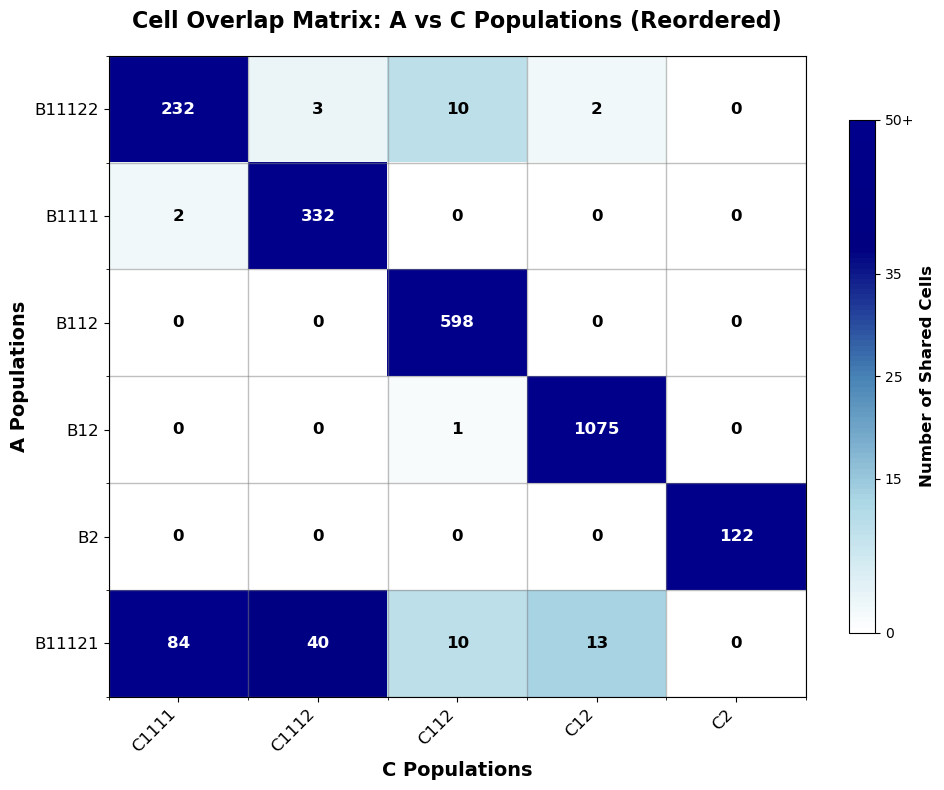

In [73]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")


Overlap Matrix (A rows vs B cols):
Pop        C1111   C1112    C112     C12      C2
A11          303     320     553      23       0
A12           15      55      66    1067       0
A2             0       0       0       0     122


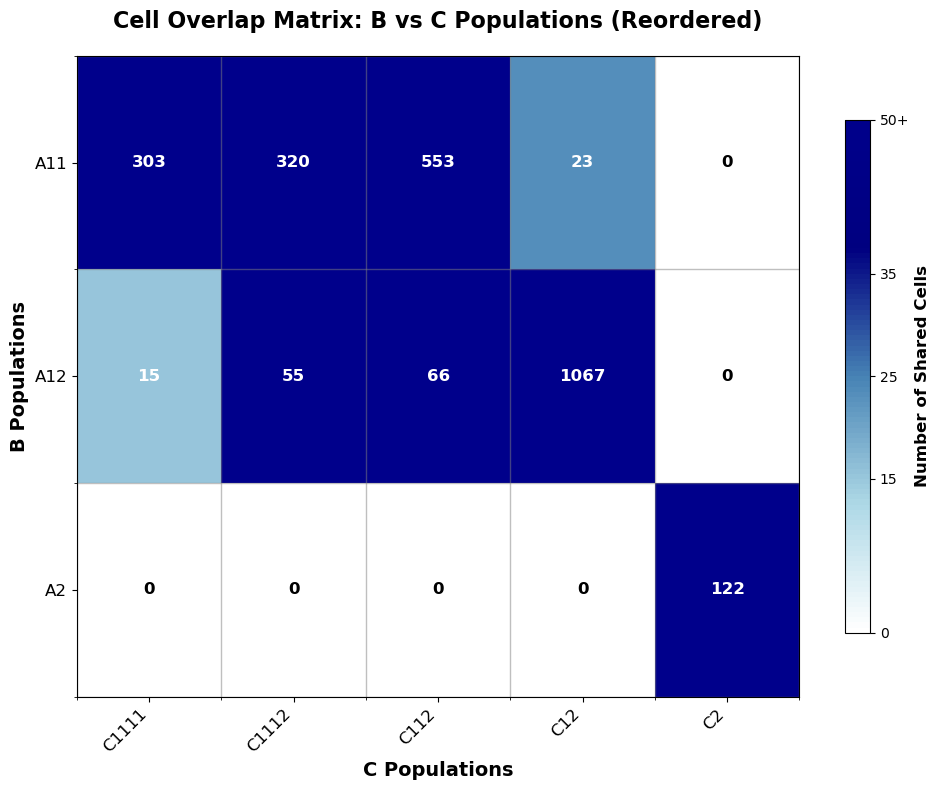

In [74]:
overlap_df = plot_overlap_matrix_figure(B_dict, C_dict, name1="B", name2="C")

In [75]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
all_data_no_WGS = data_no_WGS[cells].copy()

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_33377/166721051.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[cell] = bincounts[cell].values
/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_33377/166721051.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_no_WGS[cell] = bincounts_no_WGS[cell].values
/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_33377/166721051.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many ti

In [76]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: B2
Mean read count ratio for population B1111 relative to normal (B2): 1.37
Mean read count ratio for population B11121 relative to normal (B2): 1.42
Mean read count ratio for population B11122 relative to normal (B2): 1.40
Mean read count ratio for population B112 relative to normal (B2): 1.36
Mean read count ratio for population B12 relative to normal (B2): 1.35
Mean read count ratio for population B2 relative to normal (B2): 1.00
=== Population Set B Analysis ===
Normal population identified as: A2
Mean read count ratio for population A11 relative to normal (A2): 1.39
Mean read count ratio for population A12 relative to normal (A2): 1.35
Mean read count ratio for population A2 relative to normal (A2): 1.00
=== Population Set C Analysis ===
Normal population identified as: C2
Mean read count ratio for population C1111 relative to normal (C2): 1.42
Mean read count ratio for population C1112 relative to normal (C2): 1.3

In [77]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [78]:
A_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t", index = False)
B_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t", index = False)
C_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t", index = False)
D_df.to_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t", index = False)

In [79]:
# A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
# A_dict = {}
# for cluster in A_df['population'].unique():
#     print(cluster)
#     cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
#     A_dict[cluster] = {
#         'cells': cells_in_cluster
#     }
# avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
# relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)

In [80]:
data_lengths = data["abend"] - data["abstart"]

In [81]:
# plot_uniformity_histograms_nice(
#     all_data, 
#     A_dict, 
#     data_lengths, 
#     uniformity_data=None,  # Optional: will compute if not provided
#     title_prefix="Populations from WGS bins - ", 
#     figsize=(12, 8)
# )

In [82]:
# Display the ratios dataframes
print("Population A ratios:")
print(ratios_A.head())

print("\nPopulation B ratios:")
print(ratios_B.head())

Population A ratios:
  chrom      start        end  segment_id  B1111_ratio  B11121_ratio  \
0  chr1          0   15737727           0     1.425393      1.402706   
1  chr1   16309376   32536150           1     0.902939      0.883313   
2  chr1   33115053  149905446           2     1.595572      1.668753   
3  chr1  150480542  231431649           3     1.239143      1.263126   
4  chr1  231987328  248389233           4     1.169301      1.203091   

   B11122_ratio  B112_ratio  B12_ratio  B2_ratio  
0      1.360956    1.319472   1.327769       1.0  
1      0.855821    0.824108   0.840547       1.0  
2      1.568791    1.547252   1.585848       1.0  
3      1.237368    1.206485   1.246242       1.0  
4      1.186502    1.181414   1.208496       1.0  

Population B ratios:
  chrom      start        end  segment_id  A11_ratio  A12_ratio  A2_ratio
0  chr1          0   15737727           0   1.372116   1.322521       1.0
1  chr1   16309376   32536150           1   0.856913   0.841748       

In [83]:
relative_counts_A

{'B1111': np.float64(1.3675419957507955),
 'B11121': np.float64(1.4206677814391087),
 'B11122': np.float64(1.40038971065496),
 'B112': np.float64(1.3630832595634526),
 'B12': np.float64(1.3548858312247205),
 'B2': np.float64(1.0)}

In [84]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

Normal population: B2
Populations to optimize: ['B1111', 'B11121', 'B11122', 'B112', 'B12']

Optimizing ploidy for population: B1111

Optimal Results for B1111:
Optimal multiplier (m): 2.600
Minimum cost: 1.35e+08
Average copy number: 3.50
Found 6 local minima
Optimal multiplier for B1111: 2.600

Optimizing ploidy for population: B11121

Optimal Results for B11121:
Optimal multiplier (m): 2.300
Minimum cost: 1.47e+08
Average copy number: 3.27
Found 7 local minima
Optimal multiplier for B11121: 2.300

Optimizing ploidy for population: B11122

Optimal Results for B11122:
Optimal multiplier (m): 2.500
Minimum cost: 1.04e+08
Average copy number: 3.48
Found 7 local minima
Optimal multiplier for B11122: 2.500

Optimizing ploidy for population: B112

Optimal Results for B112:
Optimal multiplier (m): 2.500
Minimum cost: 1.18e+08
Average copy number: 3.41
Found 7 local minima
Optimal multiplier for B112: 2.500

Optimizing ploidy for population: B12

Optimal Results for B12:
Optimal multiplier (

In [85]:
# In your existing ploidy optimization loop, just modify the function call:
for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Get local minima along with the usual results
    optimal_m, min_cost, results_df, cost_results, local_minima = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1, 
        find_local_minima=True,  # Add this parameter
        window_size=2           # Optional: adjust window size
    )
    
    # Store results including local minima
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results,
        'local_minima': local_minima  # Add this
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")
    print(f"Found {len(local_minima)} local minima: {[f'{m:.2f}' for m, _ in local_minima[:5]]}")


Optimizing ploidy for population: B1111

Optimal Results for B1111:
Optimal multiplier (m): 2.600
Minimum cost: 1.35e+08
Average copy number: 3.50
Found 6 local minima
Optimal multiplier for B1111: 2.600
Found 6 local minima: ['2.60', '3.90', '4.90', '5.70', '3.30']

Optimizing ploidy for population: B11121

Optimal Results for B11121:
Optimal multiplier (m): 2.300
Minimum cost: 1.47e+08
Average copy number: 3.27
Found 7 local minima
Optimal multiplier for B11121: 2.300
Found 7 local minima: ['2.30', '5.50', '3.50', '4.80', '3.00']

Optimizing ploidy for population: B11122

Optimal Results for B11122:
Optimal multiplier (m): 2.500
Minimum cost: 1.04e+08
Average copy number: 3.48
Found 7 local minima
Optimal multiplier for B11122: 2.500
Found 7 local minima: ['2.50', '3.20', '3.90', '5.80', '4.50']

Optimizing ploidy for population: B112

Optimal Results for B112:
Optimal multiplier (m): 2.500
Minimum cost: 1.18e+08
Average copy number: 3.41
Found 7 local minima
Optimal multiplier for 


Plotting results for population: B1111


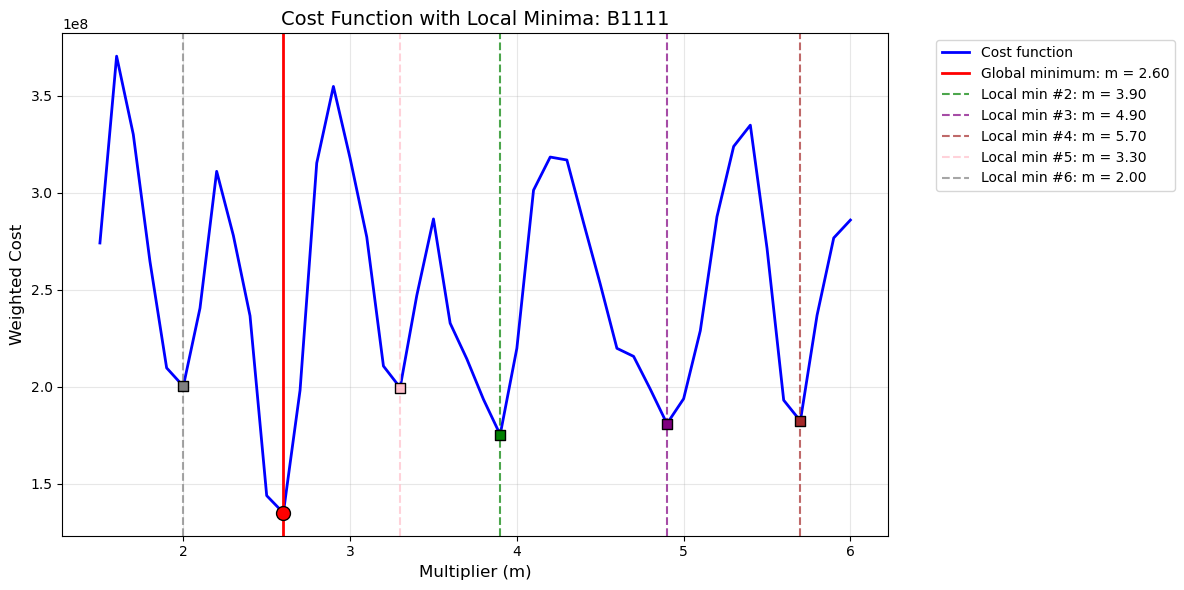


Local Minima Summary for B1111:
--------------------------------------------------
#1: m = 2.60, cost = 1.35e+08 (GLOBAL)
#2: m = 3.90, cost = 1.75e+08
#3: m = 4.90, cost = 1.81e+08
#4: m = 5.70, cost = 1.82e+08
#5: m = 3.30, cost = 2.00e+08
#6: m = 2.00, cost = 2.00e+08


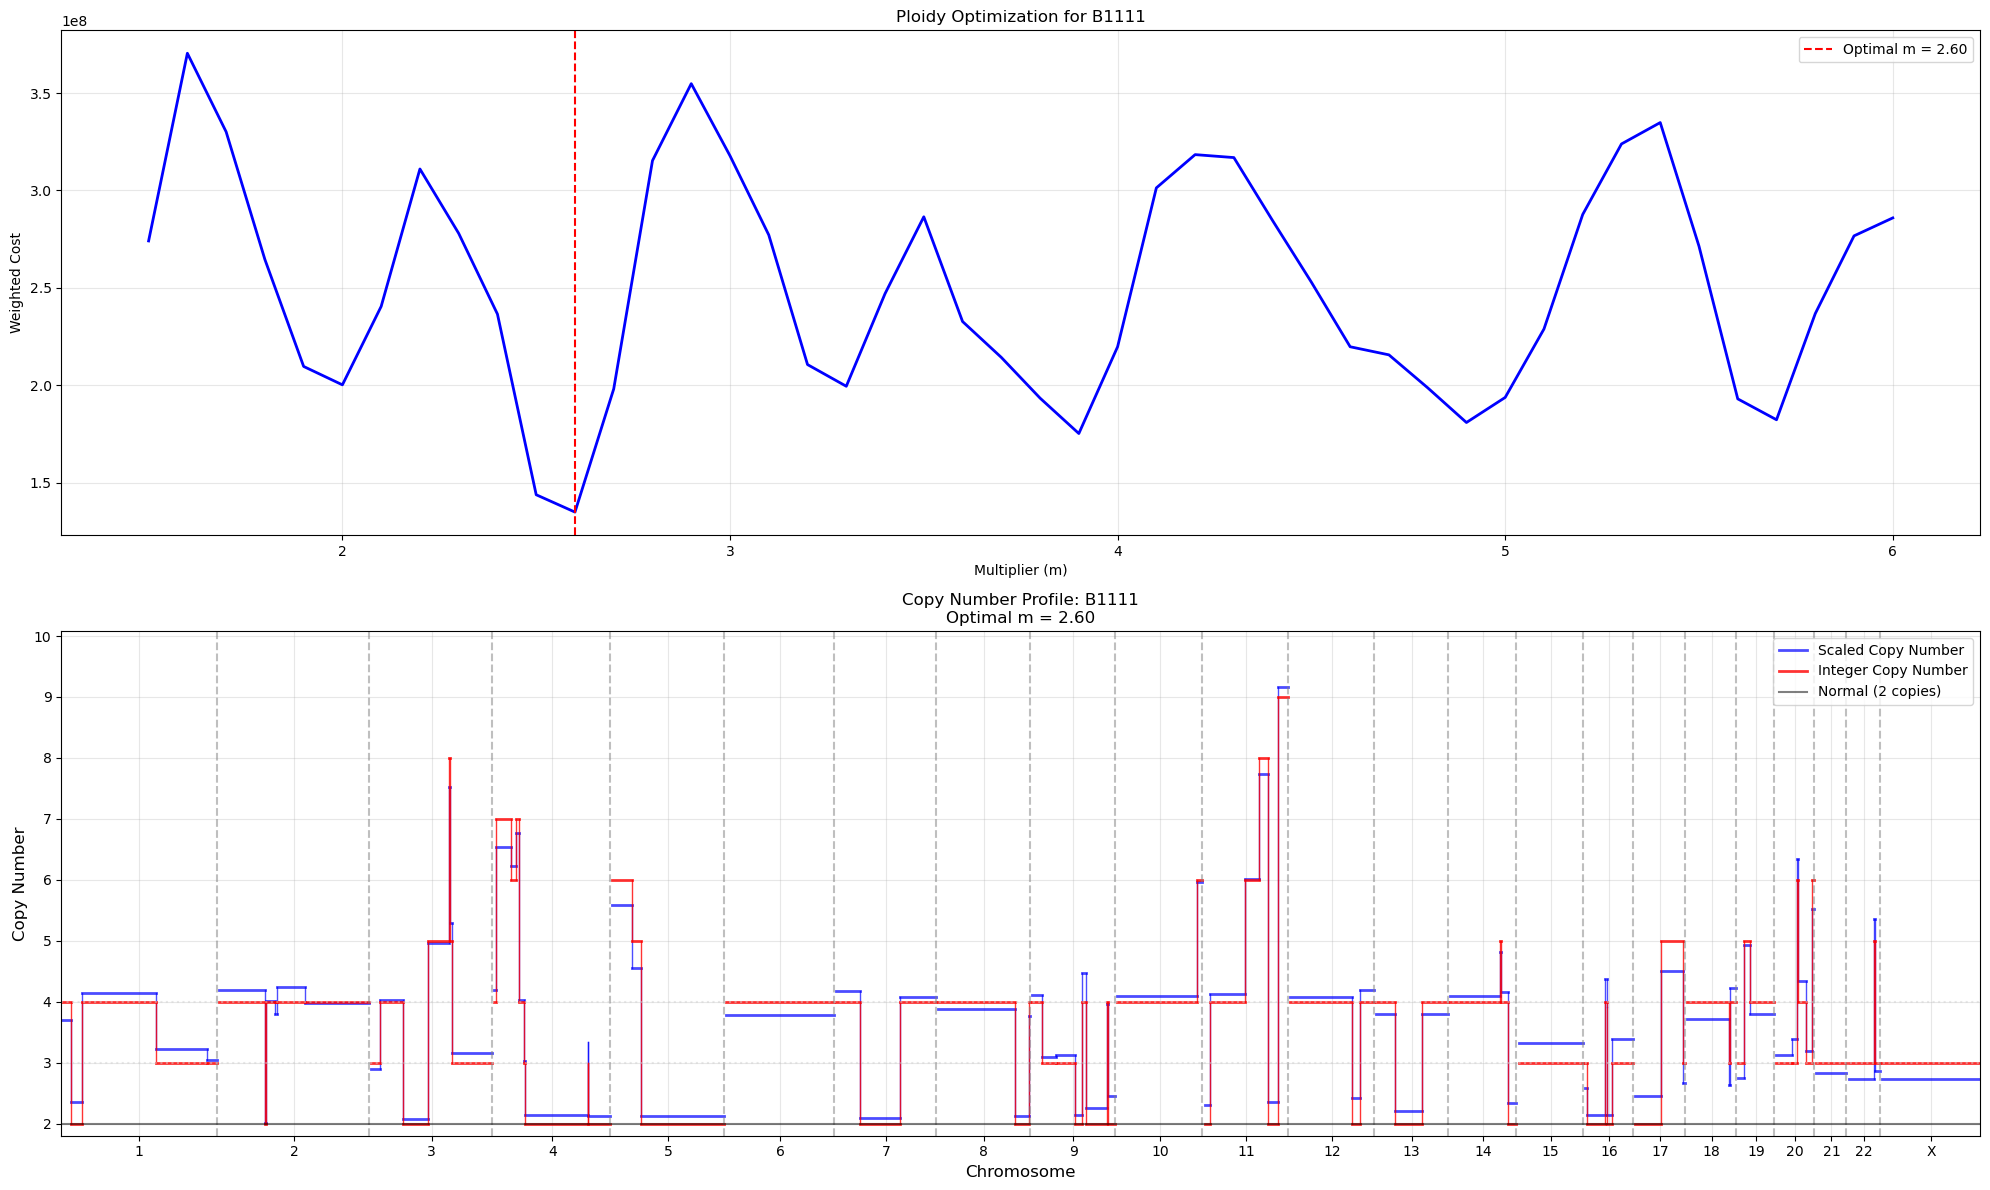

Completed plots for B1111

Plotting results for population: B11121


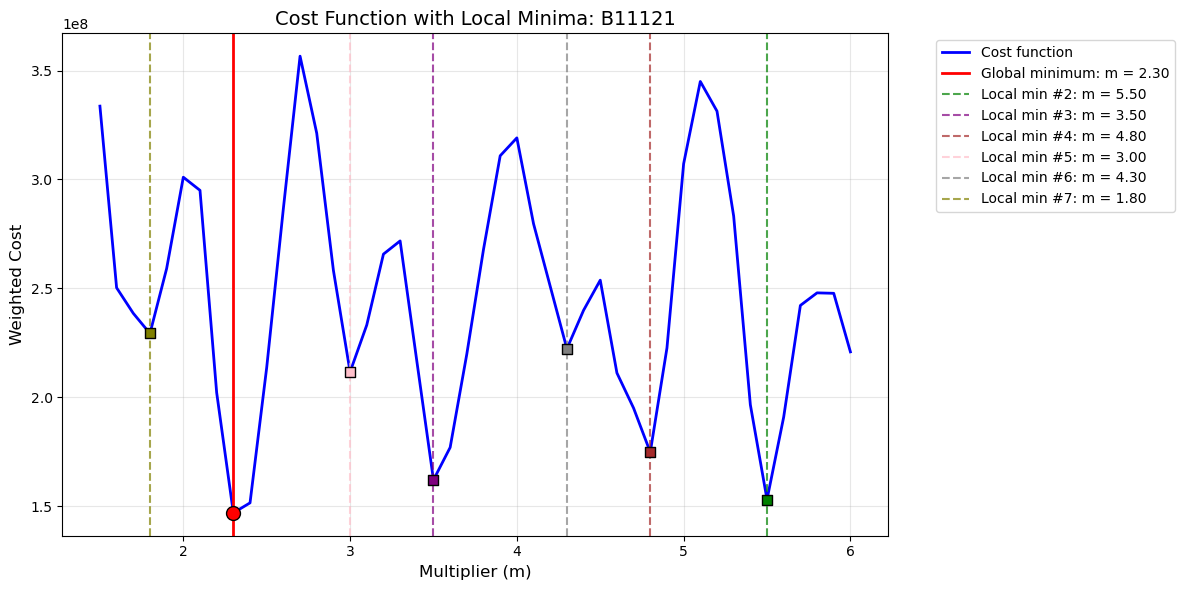


Local Minima Summary for B11121:
--------------------------------------------------
#1: m = 2.30, cost = 1.47e+08 (GLOBAL)
#2: m = 5.50, cost = 1.53e+08
#3: m = 3.50, cost = 1.62e+08
#4: m = 4.80, cost = 1.75e+08
#5: m = 3.00, cost = 2.12e+08
#6: m = 4.30, cost = 2.22e+08
#7: m = 1.80, cost = 2.29e+08


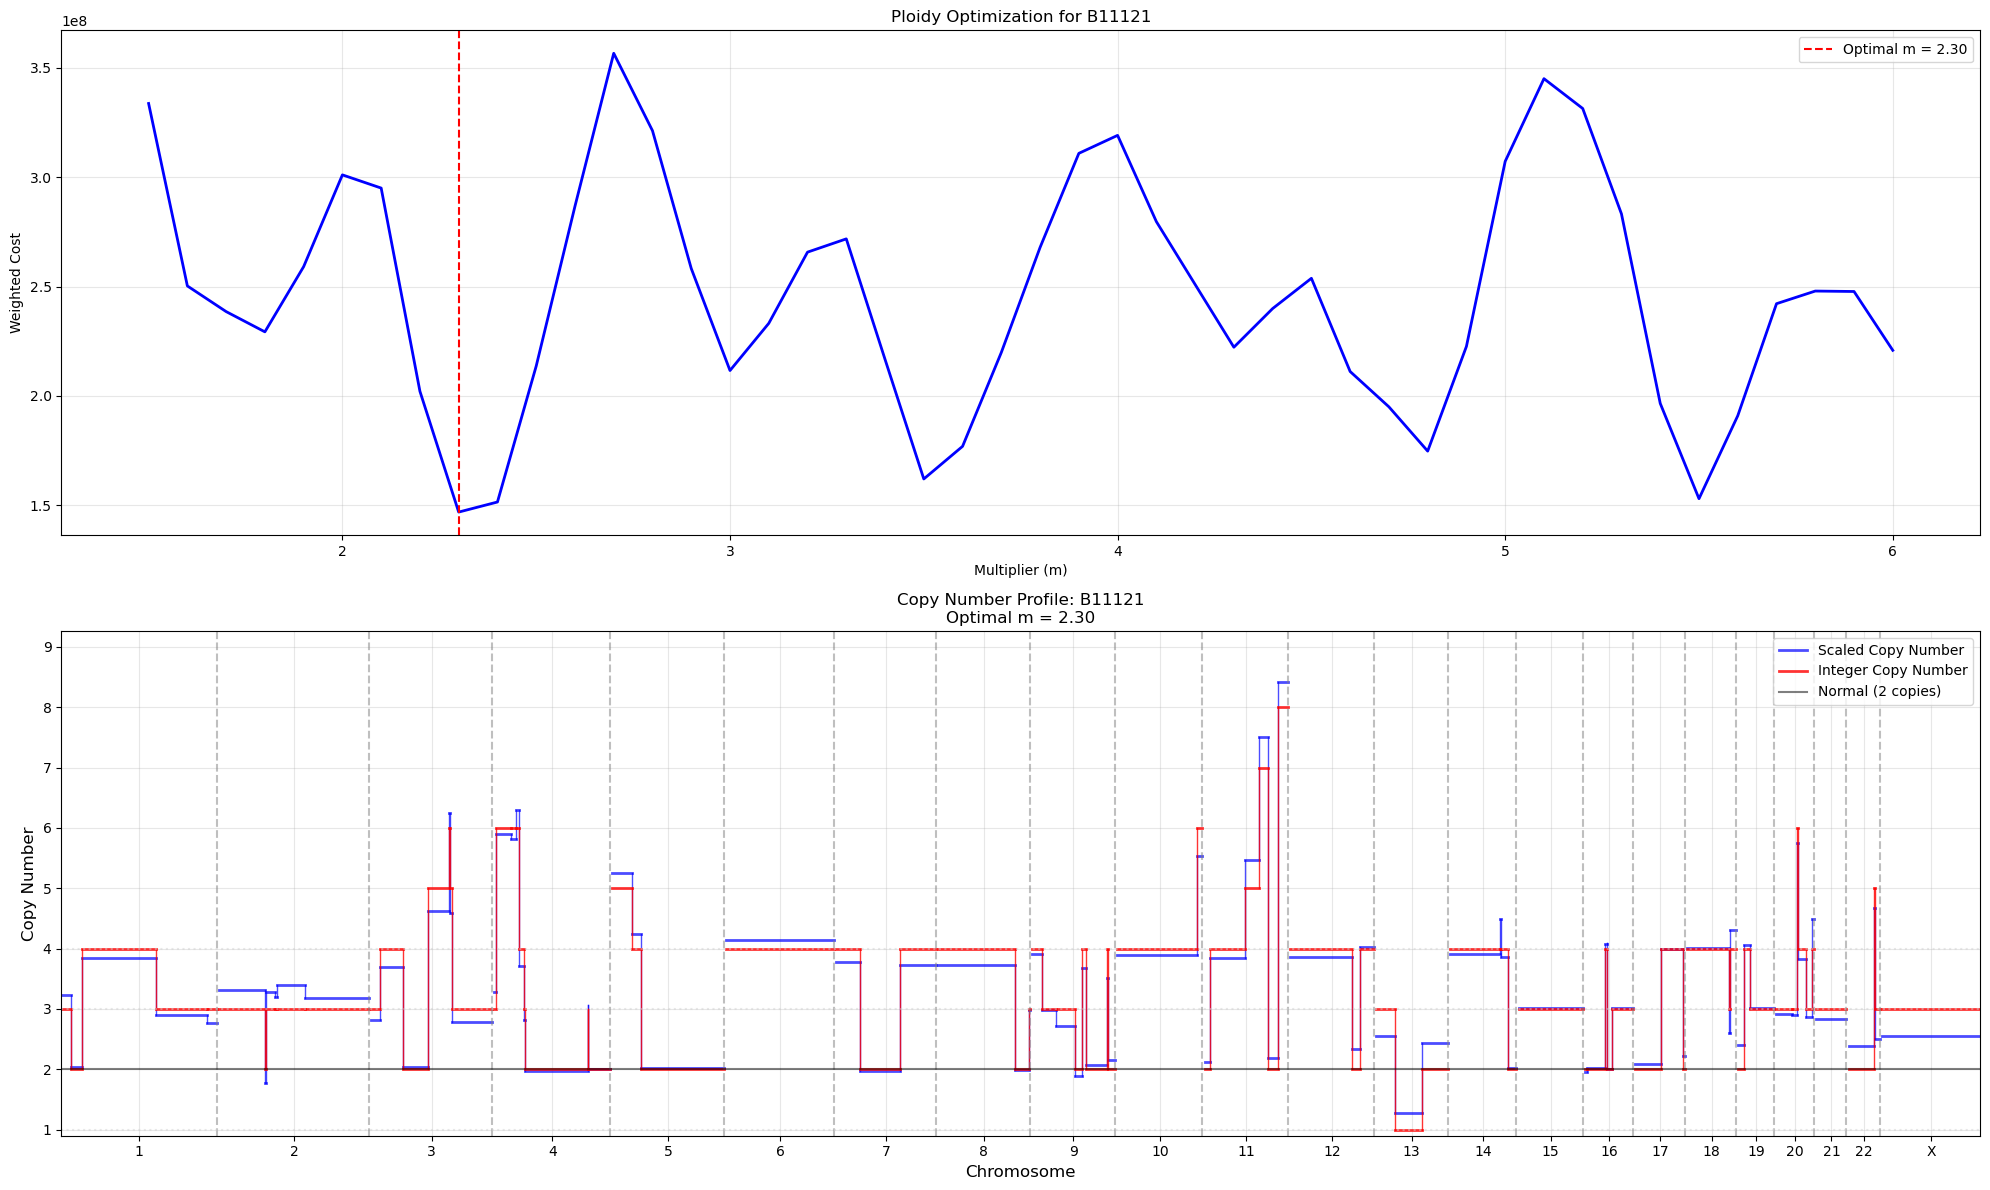

Completed plots for B11121

Plotting results for population: B11122


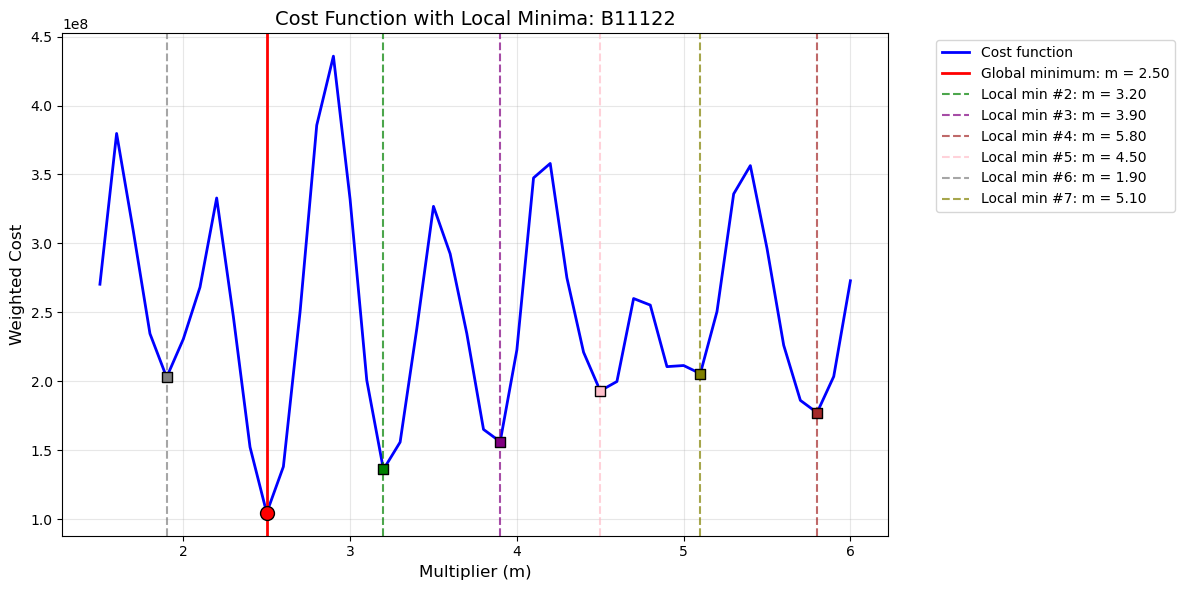


Local Minima Summary for B11122:
--------------------------------------------------
#1: m = 2.50, cost = 1.04e+08 (GLOBAL)
#2: m = 3.20, cost = 1.36e+08
#3: m = 3.90, cost = 1.56e+08
#4: m = 5.80, cost = 1.77e+08
#5: m = 4.50, cost = 1.93e+08
#6: m = 1.90, cost = 2.03e+08
#7: m = 5.10, cost = 2.06e+08


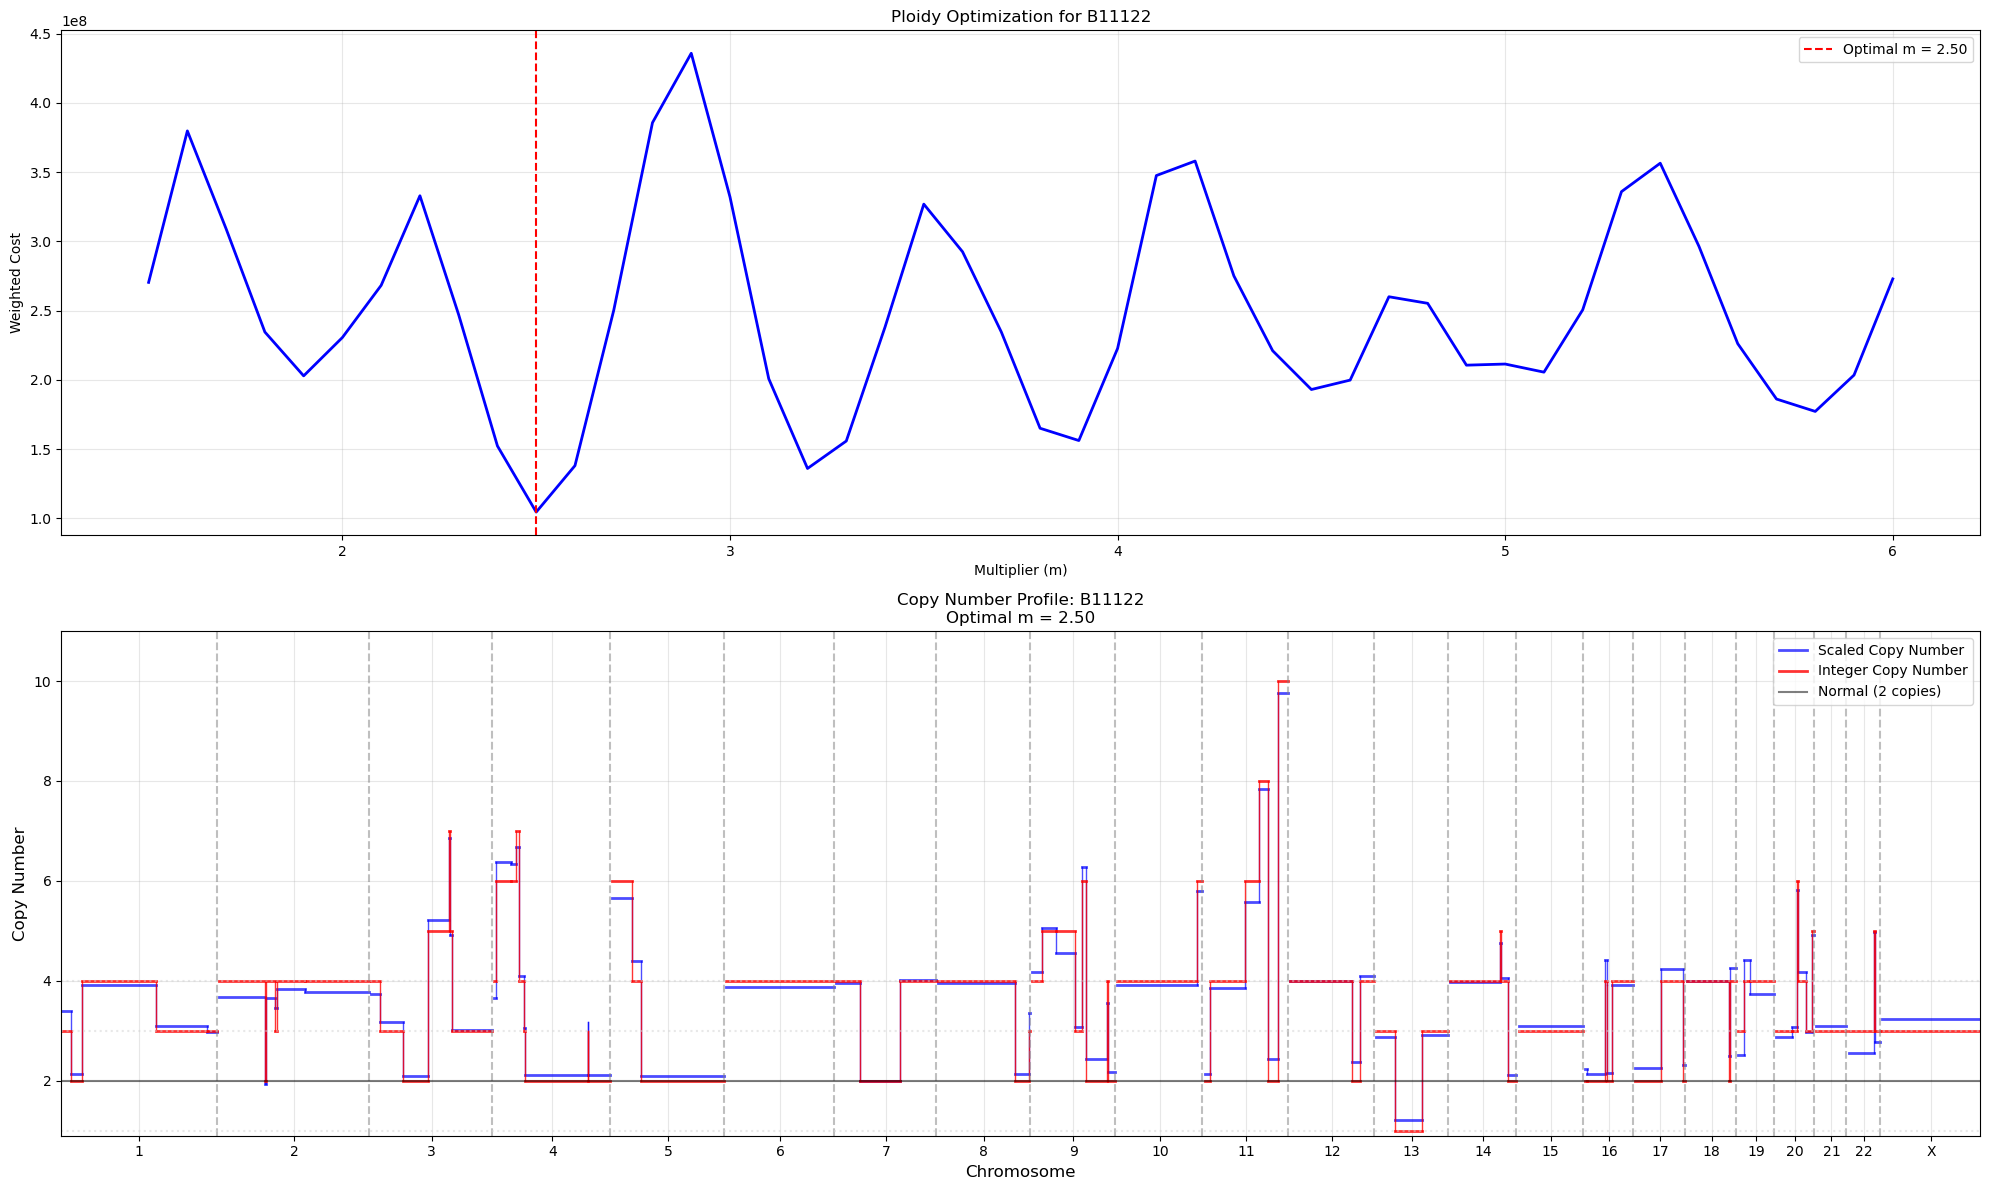

Completed plots for B11122

Plotting results for population: B112


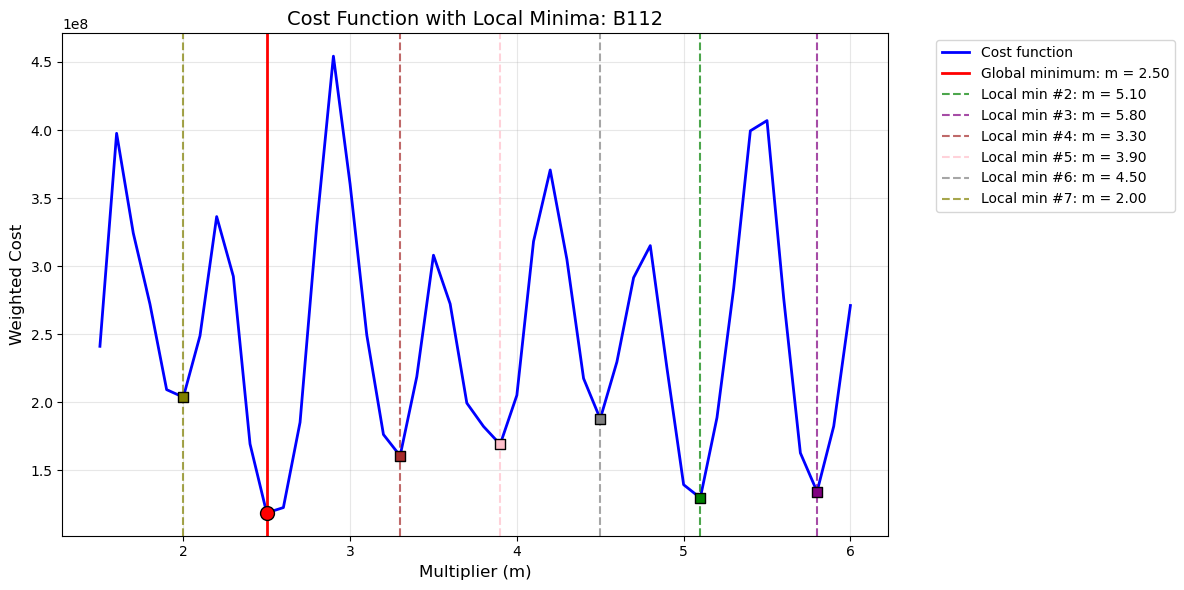


Local Minima Summary for B112:
--------------------------------------------------
#1: m = 2.50, cost = 1.18e+08 (GLOBAL)
#2: m = 5.10, cost = 1.29e+08
#3: m = 5.80, cost = 1.34e+08
#4: m = 3.30, cost = 1.60e+08
#5: m = 3.90, cost = 1.69e+08
#6: m = 4.50, cost = 1.88e+08
#7: m = 2.00, cost = 2.04e+08


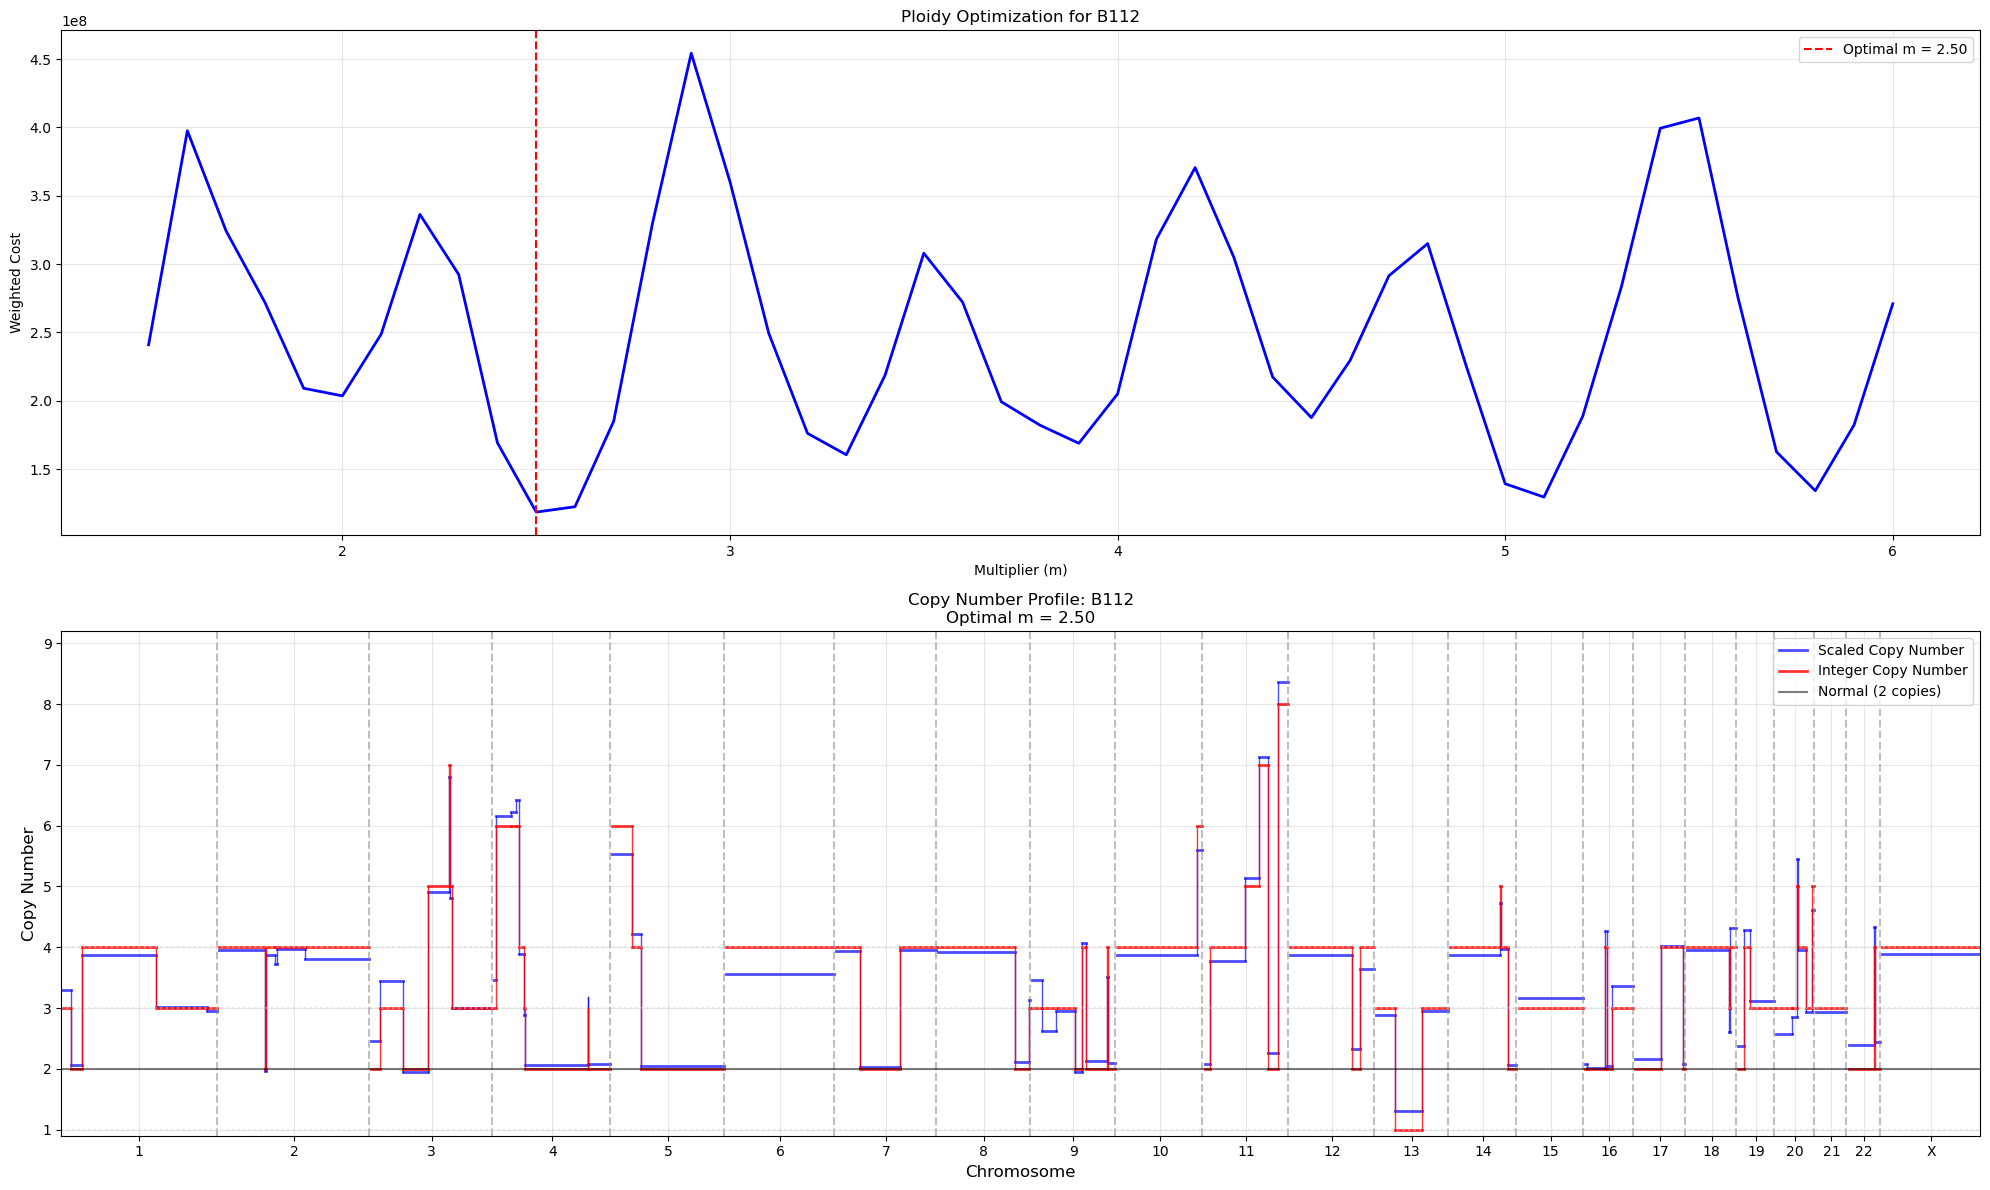

Completed plots for B112

Plotting results for population: B12


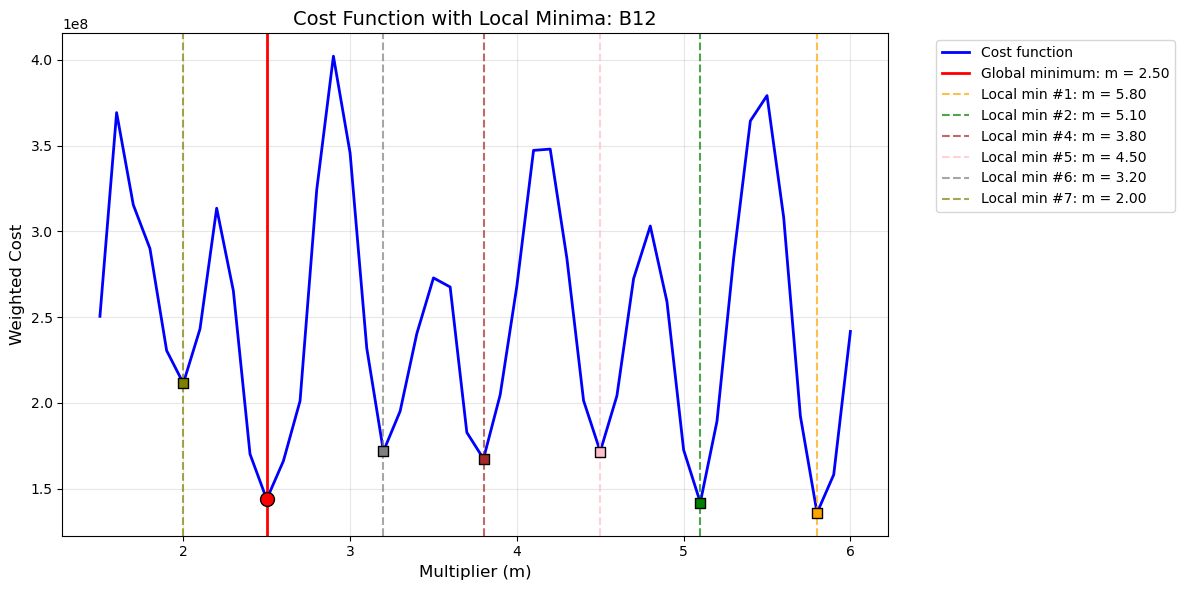


Local Minima Summary for B12:
--------------------------------------------------
#1: m = 5.80, cost = 1.36e+08
#2: m = 5.10, cost = 1.42e+08
#3: m = 2.50, cost = 1.44e+08 (GLOBAL)
#4: m = 3.80, cost = 1.67e+08
#5: m = 4.50, cost = 1.72e+08
#6: m = 3.20, cost = 1.72e+08
#7: m = 2.00, cost = 2.11e+08


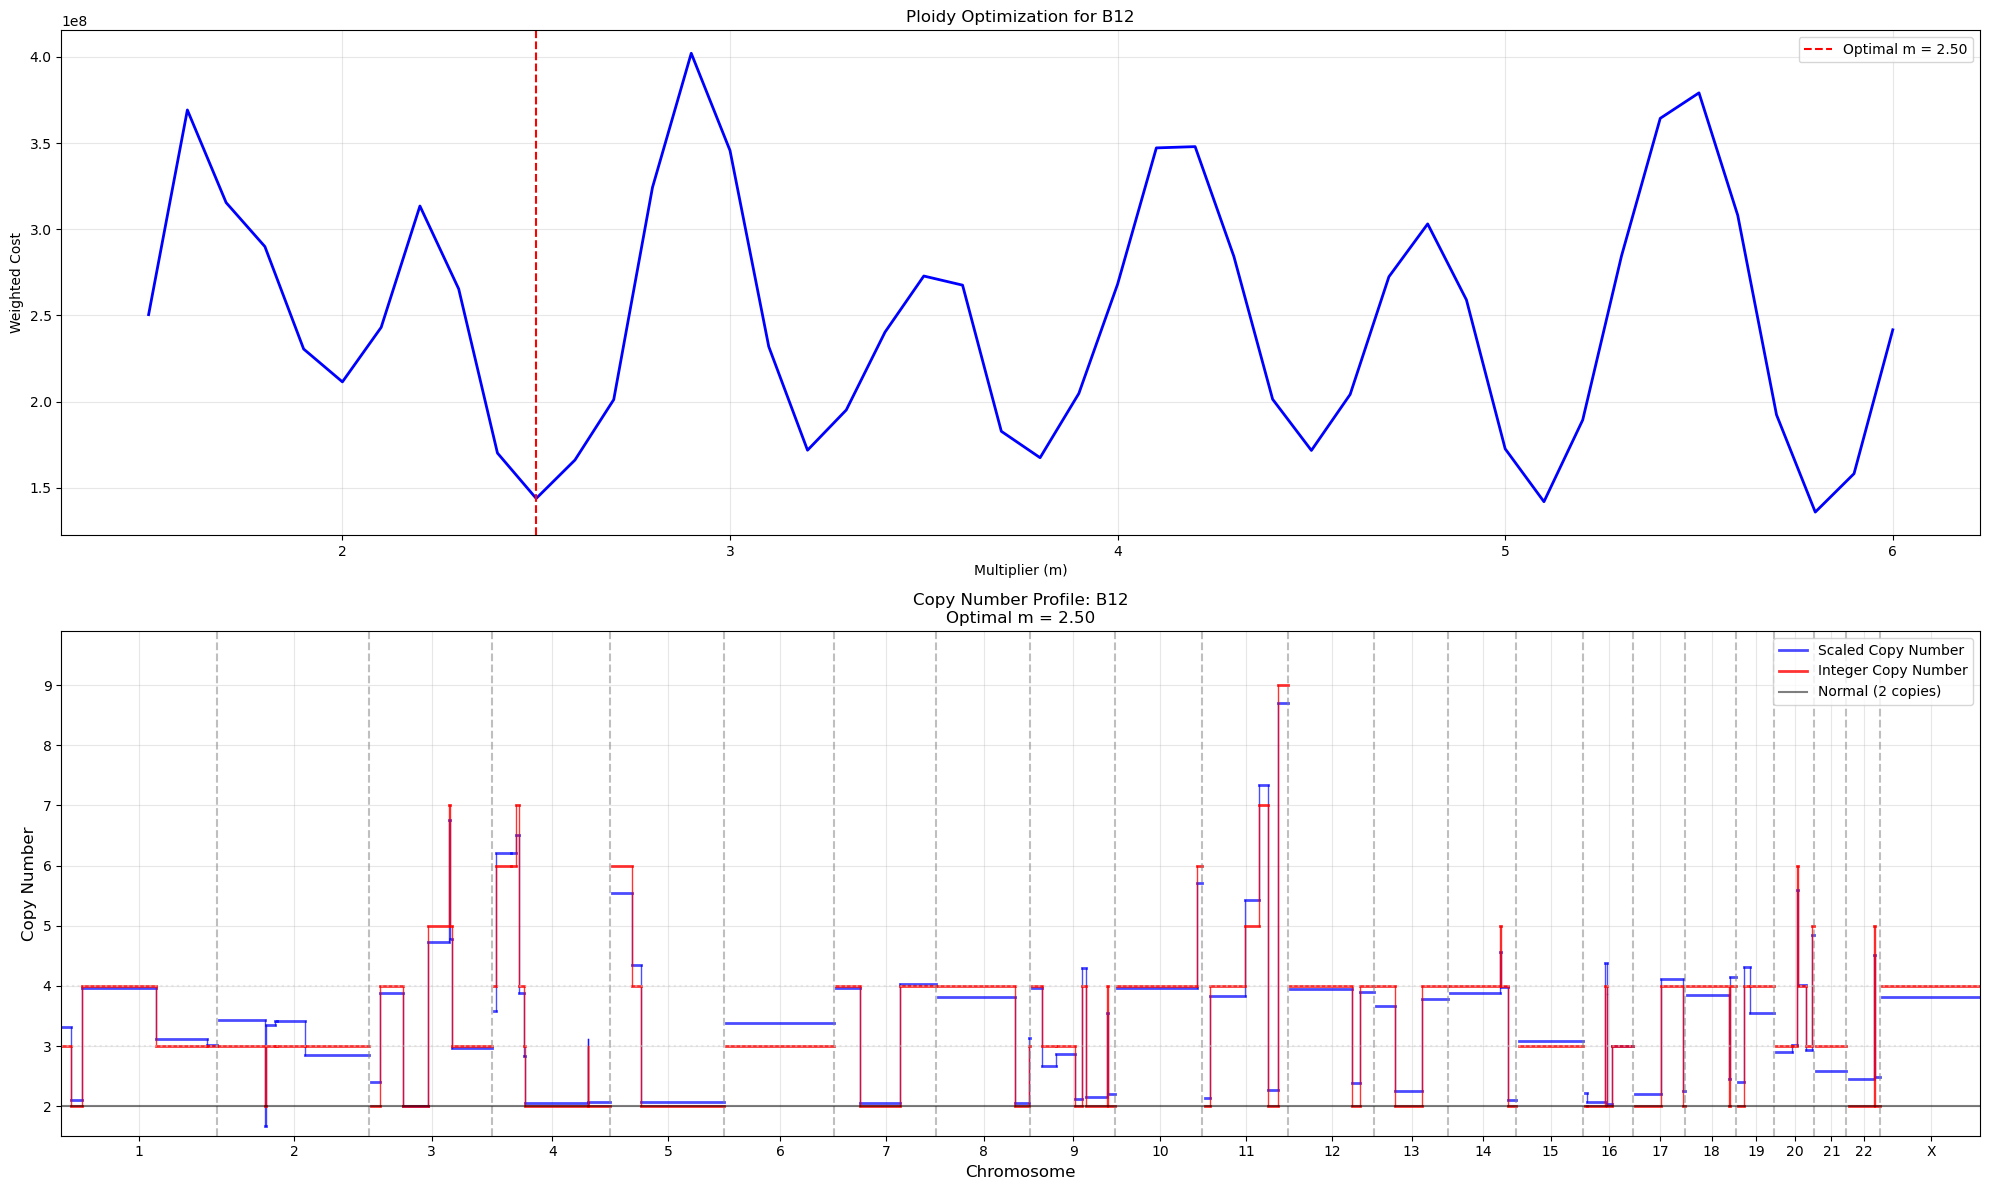

Completed plots for B12


In [86]:
# Test the plotting functions on your ploidy results
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Plotting results for population: {pop_name}")
    
    # Get the results for this population
    results = ploidy_results_A[pop_name]
    profile_df = profile_dfs_A[pop_name]
    
    # 1. Plot cost function with local minima
    plot_cost_function_with_minima(
        cost_results=results['cost_results'],
        local_minima=results['local_minima'],
        pop_name=pop_name,
        optimal_m=results['optimal_multiplier']
    )
    
    # 2. Plot the full ploidy optimization (cost function + copy number profile)
    pop_col = f"{pop_name}_ratio"  # Reconstruct the column name
    plot_ploidy_optimization(
        results_df=profile_df,
        cost_results=results['cost_results'],
        optimal_m=results['optimal_multiplier'],
        pop_col=pop_col
    )
    
    print(f"Completed plots for {pop_name}")

In [87]:
import os
import pandas as pd

# Define the parquet file path
parquet_file = f"../data/{tumor}/hap_count_df.parquet"

# Check if parquet file exists, if so load it, otherwise create and save it
if os.path.exists(parquet_file):
    print("Loading hap_count_df from parquet file...")
    hap_count_df = pd.read_parquet(parquet_file)
    print(f"Loaded hap_count_df with shape: {hap_count_df.shape}")
else:
    print("Parquet file not found. Creating hap_count_df from source data...")
    
    hap_count_df = pd.read_csv(f"/mnt/wigstore6/user/ranade/binless_clustering/DNA_alone/{tumor}/per_cell_hap_count.txt", sep = "\t")
    binning = pd.read_csv("/mnt/wigstore3/user/kendall/hg19.50mer/hg19.varbin.gc.content.2.5k.bowtie.k50.txt", sep='\t')
    bin_loc_dict = dict(zip(binning.index, binning["bin.start.abspos"]))
    chrom_dict = dict(zip(binning.index, binning["bin.chrom"]))

    hap_count_df["abspos"] = hap_count_df["bin"].apply(lambda x : bin_loc_dict[x])
    hap_count_df["chrom"] = hap_count_df["bin"].apply(lambda x : chrom_dict[x])
    hap_count_df= hap_count_df[["chrom", "abspos","bin", "cell", "hap_count","Total"]]

    print(f"Created hap_count_df with shape: {hap_count_df.shape}")
    
    # Save as parquet for future use
    print("Saving hap_count_df as parquet file...")
    hap_count_df.to_parquet(parquet_file, index=False)
    
    # Check file size
    file_size = os.path.getsize(parquet_file)
    print(f"Saved parquet file: {file_size:,} bytes ({file_size/1024**2:.2f} MB)")

print("hap_count_df ready for analysis!")

Loading hap_count_df from parquet file...
Loaded hap_count_df with shape: (8083512, 6)
hap_count_df ready for analysis!


In [88]:
hap_count_df.head()

,chrom,abspos,bin,cell,hap_count,Total
0,chr1,0,0,GAAAGCGACCATACAAT,3,3
1,chr1,1925685,1,GAAAGCGACCATACAAT,3,3
2,chr1,3106884,2,GAAAGCGACCATACAAT,2,2
3,chr1,4351684,3,GAAAGCGACCATACAAT,2,8
4,chr1,5438445,4,GAAAGCGACCATACAAT,1,3


In [89]:
bin_to_chrom_dict = dict(zip(hap_count_df[["chrom", "bin"]].drop_duplicates()["bin"].values, hap_count_df[["chrom", "bin"]].drop_duplicates()["chrom"].values))

In [90]:
example = list(A_dict.keys())[1]

In [91]:
# # Example usage for A211 with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,  # or use ploidy_results_A[example]['optimal_multiplier']
#     local_m=3.1,   # pick from ploidy_results_A[example]['local_minima']
#     pop_col=f'{example}_ratio'
# )

In [92]:
#Get all cells in example
example_cells = A_dict[example]['cells']
#Filter hap_count_df for these cells
example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
example_hap_ratio['hap_ratio'] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
example_hap_ratio['folded'] = example_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information    
example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])

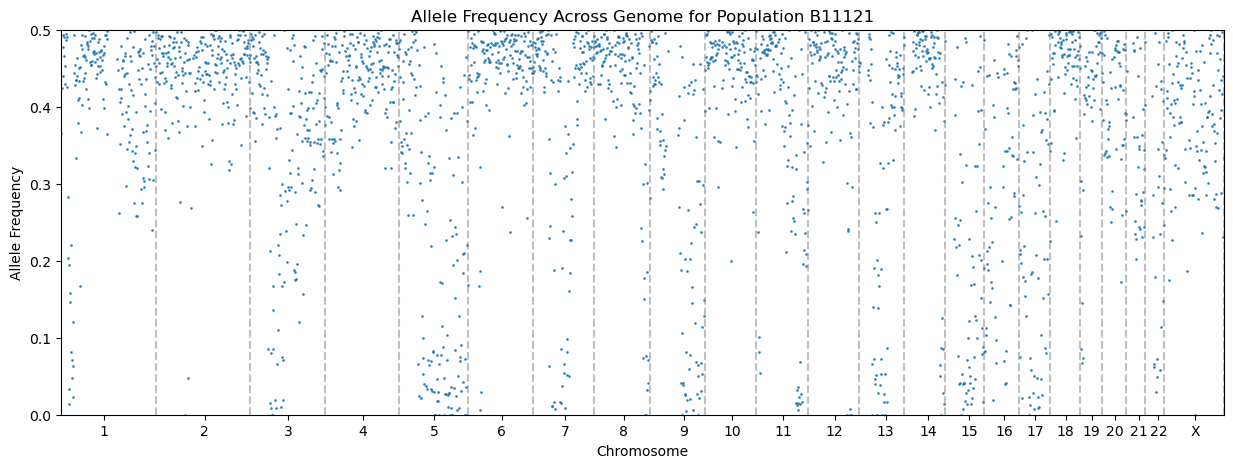

In [93]:
# plot the folded allele frequency along the genome
example_hap_ratio_sorted = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(example_hap_ratio_sorted['abspos'], example_hap_ratio_sorted['folded'], s=1, alpha=0.8)
plt.xlabel('Chromosome')
plt.ylabel('Allele Frequency')
plt.title('Allele Frequency Across Genome for Population ' + example)
# Add vertical lines for chromosome boundaries
chrom_boundaries = example_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = example_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(example_hap_ratio_sorted['abspos'].min(), example_hap_ratio_sorted['abspos'].max())
plt.show()

In [94]:
hap_df_dict = {}
hap_summary_df = pd.DataFrame()
for pop_name in A_dict.keys():
    #Get all cells in example
    example_cells = A_dict[pop_name]['cells']
    #Filter hap_count_df for these cells
    example_hap_df = hap_count_df[hap_count_df['cell'].isin(example_cells)].copy()
    # compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
    example_hap_ratio = example_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
    example_hap_ratio['hap_ratio_'+pop_name] = example_hap_ratio['hap_count'] / example_hap_ratio['Total']
    example_hap_ratio.rename(columns={'hap_count': 'hap_count_'+pop_name, 'Total': 'Total_'+pop_name}, inplace=True)
    example_hap_ratio['folded_'+pop_name] = example_hap_ratio['hap_ratio_'+pop_name].apply(lambda x: min(x, 1-x))
    # Add chromosome information    
    example_hap_ratio["chrom"] = example_hap_ratio["bin"].apply(lambda x : bin_to_chrom_dict[x])
    example_hap_ratio = example_hap_ratio[["bin", "abspos", "chrom", 'hap_ratio_'+pop_name, 'folded_'+pop_name, 'hap_count_'+pop_name, 'Total_'+pop_name]]
    hap_df_dict[pop_name] = example_hap_ratio.sort_values(by=['chrom', 'abspos'])
    if hap_summary_df.empty:
        hap_summary_df = example_hap_ratio.sort_values(by=['chrom', 'abspos']).copy()
    else:
        hap_summary_df = hap_summary_df.merge(
            example_hap_ratio,
            on=['bin', 'abspos', 'chrom'],
            suffixes=('', f'_{pop_name}')
        )


In [95]:
hap_summary_df

,bin,abspos,chrom,hap_ratio_B1111,folded_B1111,hap_count_B1111,Total_B1111,hap_ratio_B11121,folded_B11121,hap_count_B11121,...,hap_count_B112,Total_B112,hap_ratio_B12,folded_B12,hap_count_B12,Total_B12,hap_ratio_B2,folded_B2,hap_count_B2,Total_B2
0,0,0,chr1,0.458422,0.458422,215,469,0.365385,0.365385,76,...,354,791,0.450704,0.450704,640,1420,0.420561,0.420561,45,107
1,1,1925685,chr1,0.469388,0.469388,161,343,0.576000,0.424000,72,...,242,515,0.488701,0.488701,519,1062,0.633333,0.366667,38,60
2,2,3106884,chr1,0.542857,0.457143,304,560,0.522267,0.477733,129,...,518,915,0.515265,0.484735,827,1605,0.380597,0.380597,51,134
3,3,4351684,chr1,0.530343,0.469657,402,758,0.439430,0.439430,185,...,717,1460,0.484381,0.484381,1225,2529,0.468571,0.468571,82,175
4,4,5438445,chr1,0.419628,0.419628,248,591,0.493724,0.493724,118,...,422,854,0.463795,0.463795,743,1602,0.460000,0.460000,46,100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2483,2483,3029874983,chrX,0.385185,0.385185,52,135,0.416667,0.416667,25,...,199,347,0.446809,0.446809,273,611,0.490909,0.490909,27,55
2484,2484,3031129344,chrX,0.468647,0.468647,142,303,0.503546,0.496454,71,...,361,794,0.510161,0.489839,728,1427,0.500000,0.500000,45,90
2485,2485,3032248949,chrX,0.649606,0.350394,165,254,0.560748,0.439252,60,...,276,598,0.419469,0.419469,474,1130,0.547619,0.452381,46,84
2486,2486,3033693492,chrX,0.739130,0.260870,68,92,0.769231,0.230769,30,...,149,210,0.678474,0.321526,249,367,0.777778,0.222222,21,27


In [96]:
hap_summary_df.to_csv(f"../data/{tumor}/{tumor}_haplotype_summary_by_population_A.txt", sep="\t", index=False)

In [97]:
normal_A

'B2'

In [98]:
#Get all cells in A1
normal_cells = A_dict[normal_A]['cells']
#Filter hap_count_df for these cells
normal_hap_df = hap_count_df[hap_count_df['cell'].isin(normal_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
normal_hap_ratio = normal_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
normal_hap_ratio['hap_ratio'] = normal_hap_ratio['hap_count'] / normal_hap_ratio['Total']
normal_hap_ratio['folded'] = normal_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
normal_hap_ratio["chrom"] = normal_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])

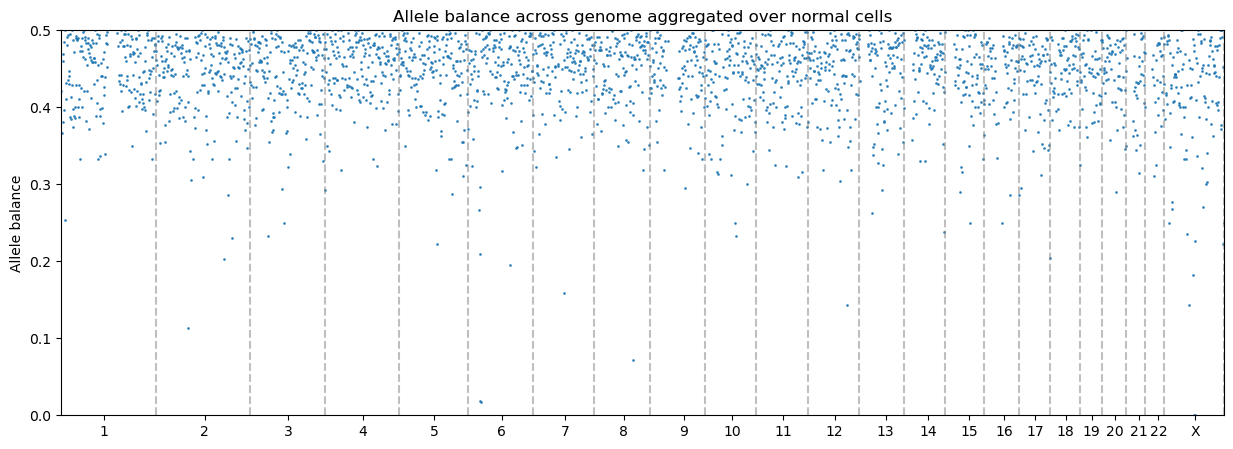

In [99]:
# plot the folded allele frequency along the genome
normal_hap_ratio_sorted = normal_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(normal_hap_ratio_sorted['abspos'], normal_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over normal cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = normal_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = normal_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(normal_hap_ratio_sorted['abspos'].min(), normal_hap_ratio_sorted['abspos'].max())
plt.show()

In [100]:
A_df.head()

,cell,population,normal_population
0,AAAACCAGCTTAAGAAG,B1111,False
1,AAAACCATAGCATAAGC,B1111,False
2,AAAACCGATGCAGCTAA,B1111,False
3,AAAACCGATGCAGTACA,B1111,False
4,AAAATGAAATCCCTACT,B1111,False


In [101]:
#Get all tumor cells in (not A1)
tumor_cells = A_df[A_df['population'] != normal_A]['cell'].tolist()
#Filter hap_count_df for these cells
tumor_hap_df = hap_count_df[hap_count_df['cell'].isin(tumor_cells)].copy()
# compute haplotype ratio for each bin and abspos (sum of hap_count over all cells/ sum of Total over all cells)
tumor_hap_ratio = tumor_hap_df.groupby(['bin', 'abspos']).agg({'hap_count':'sum', 'Total':'sum'}).reset_index()
tumor_hap_ratio['hap_ratio'] = tumor_hap_ratio['hap_count'] / tumor_hap_ratio['Total']
tumor_hap_ratio['folded'] = tumor_hap_ratio['hap_ratio'].apply(lambda x: min(x, 1-x))
# Add chromosome information
tumor_hap_ratio["chrom"] = tumor_hap_ratio["bin"].apply(lambda x: bin_to_chrom_dict[x])


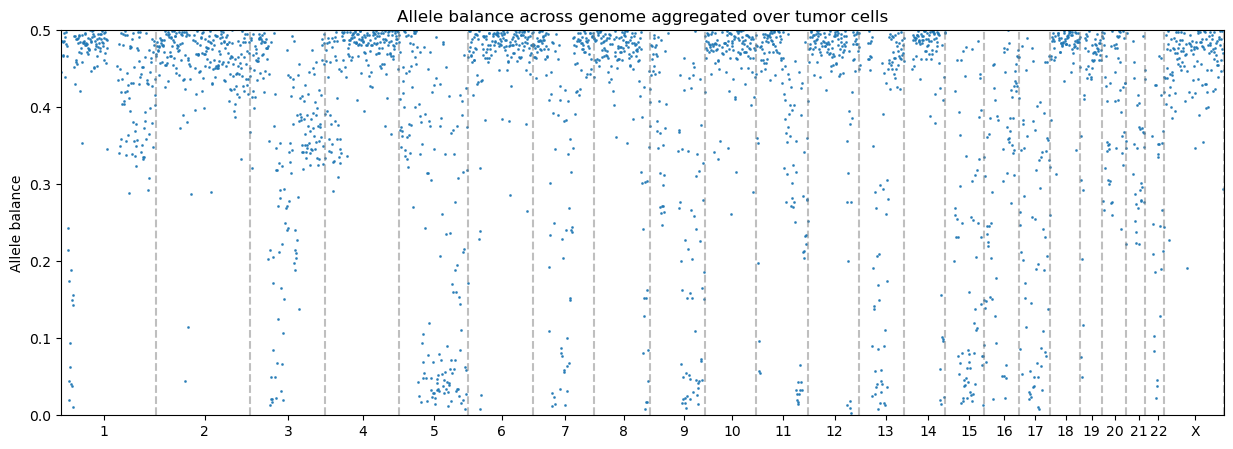

In [102]:
# plot the folded allele frequency along the genome
tumor_hap_ratio_sorted = tumor_hap_ratio.sort_values(by=['chrom', 'abspos'])
plt.figure(figsize=(15,5))
plt.scatter(tumor_hap_ratio_sorted['abspos'], tumor_hap_ratio_sorted['folded'], s=1, alpha=0.8)
#plt.xlabel('Chromosome')
plt.ylabel('Allele balance')
plt.title('Allele balance across genome aggregated over tumor cells')
# Add vertical lines for chromosome boundaries
chrom_boundaries = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].max()
for boundary in chrom_boundaries:
    plt.axvline(x=boundary, color='grey', linestyle='--', alpha=0.5)
# Add chromosome labels at midpoints
chrom_midpoints = tumor_hap_ratio_sorted.groupby('chrom')['abspos'].median()
# add chromosome labels along x ticks at midpoints and label them by chromosome number
plt.xticks(chrom_midpoints, [c[3:] for c in chrom_midpoints.index], rotation=0)
# Set y-axis limits to focus on 0 to 0.5

plt.ylim(0, 0.5)
plt.xlim(tumor_hap_ratio_sorted['abspos'].min(), tumor_hap_ratio_sorted['abspos'].max())
plt.show()

In [103]:
# # Example usage for example with global min 2.4 and local min 3.1
# plot_ploidy_comparison(
#     results_df=profile_dfs_A[example],
#     cost_results=ploidy_results_A[example]['cost_results'],
#     optimal_m=2.4,
#     local_m=3.1,
#     pop_col=example + '_ratio',
#     hap_count_df=hap_count_df,
#     cells=A_dict[example]['cells']
# )


Creating ploidy comparison for population: B1111


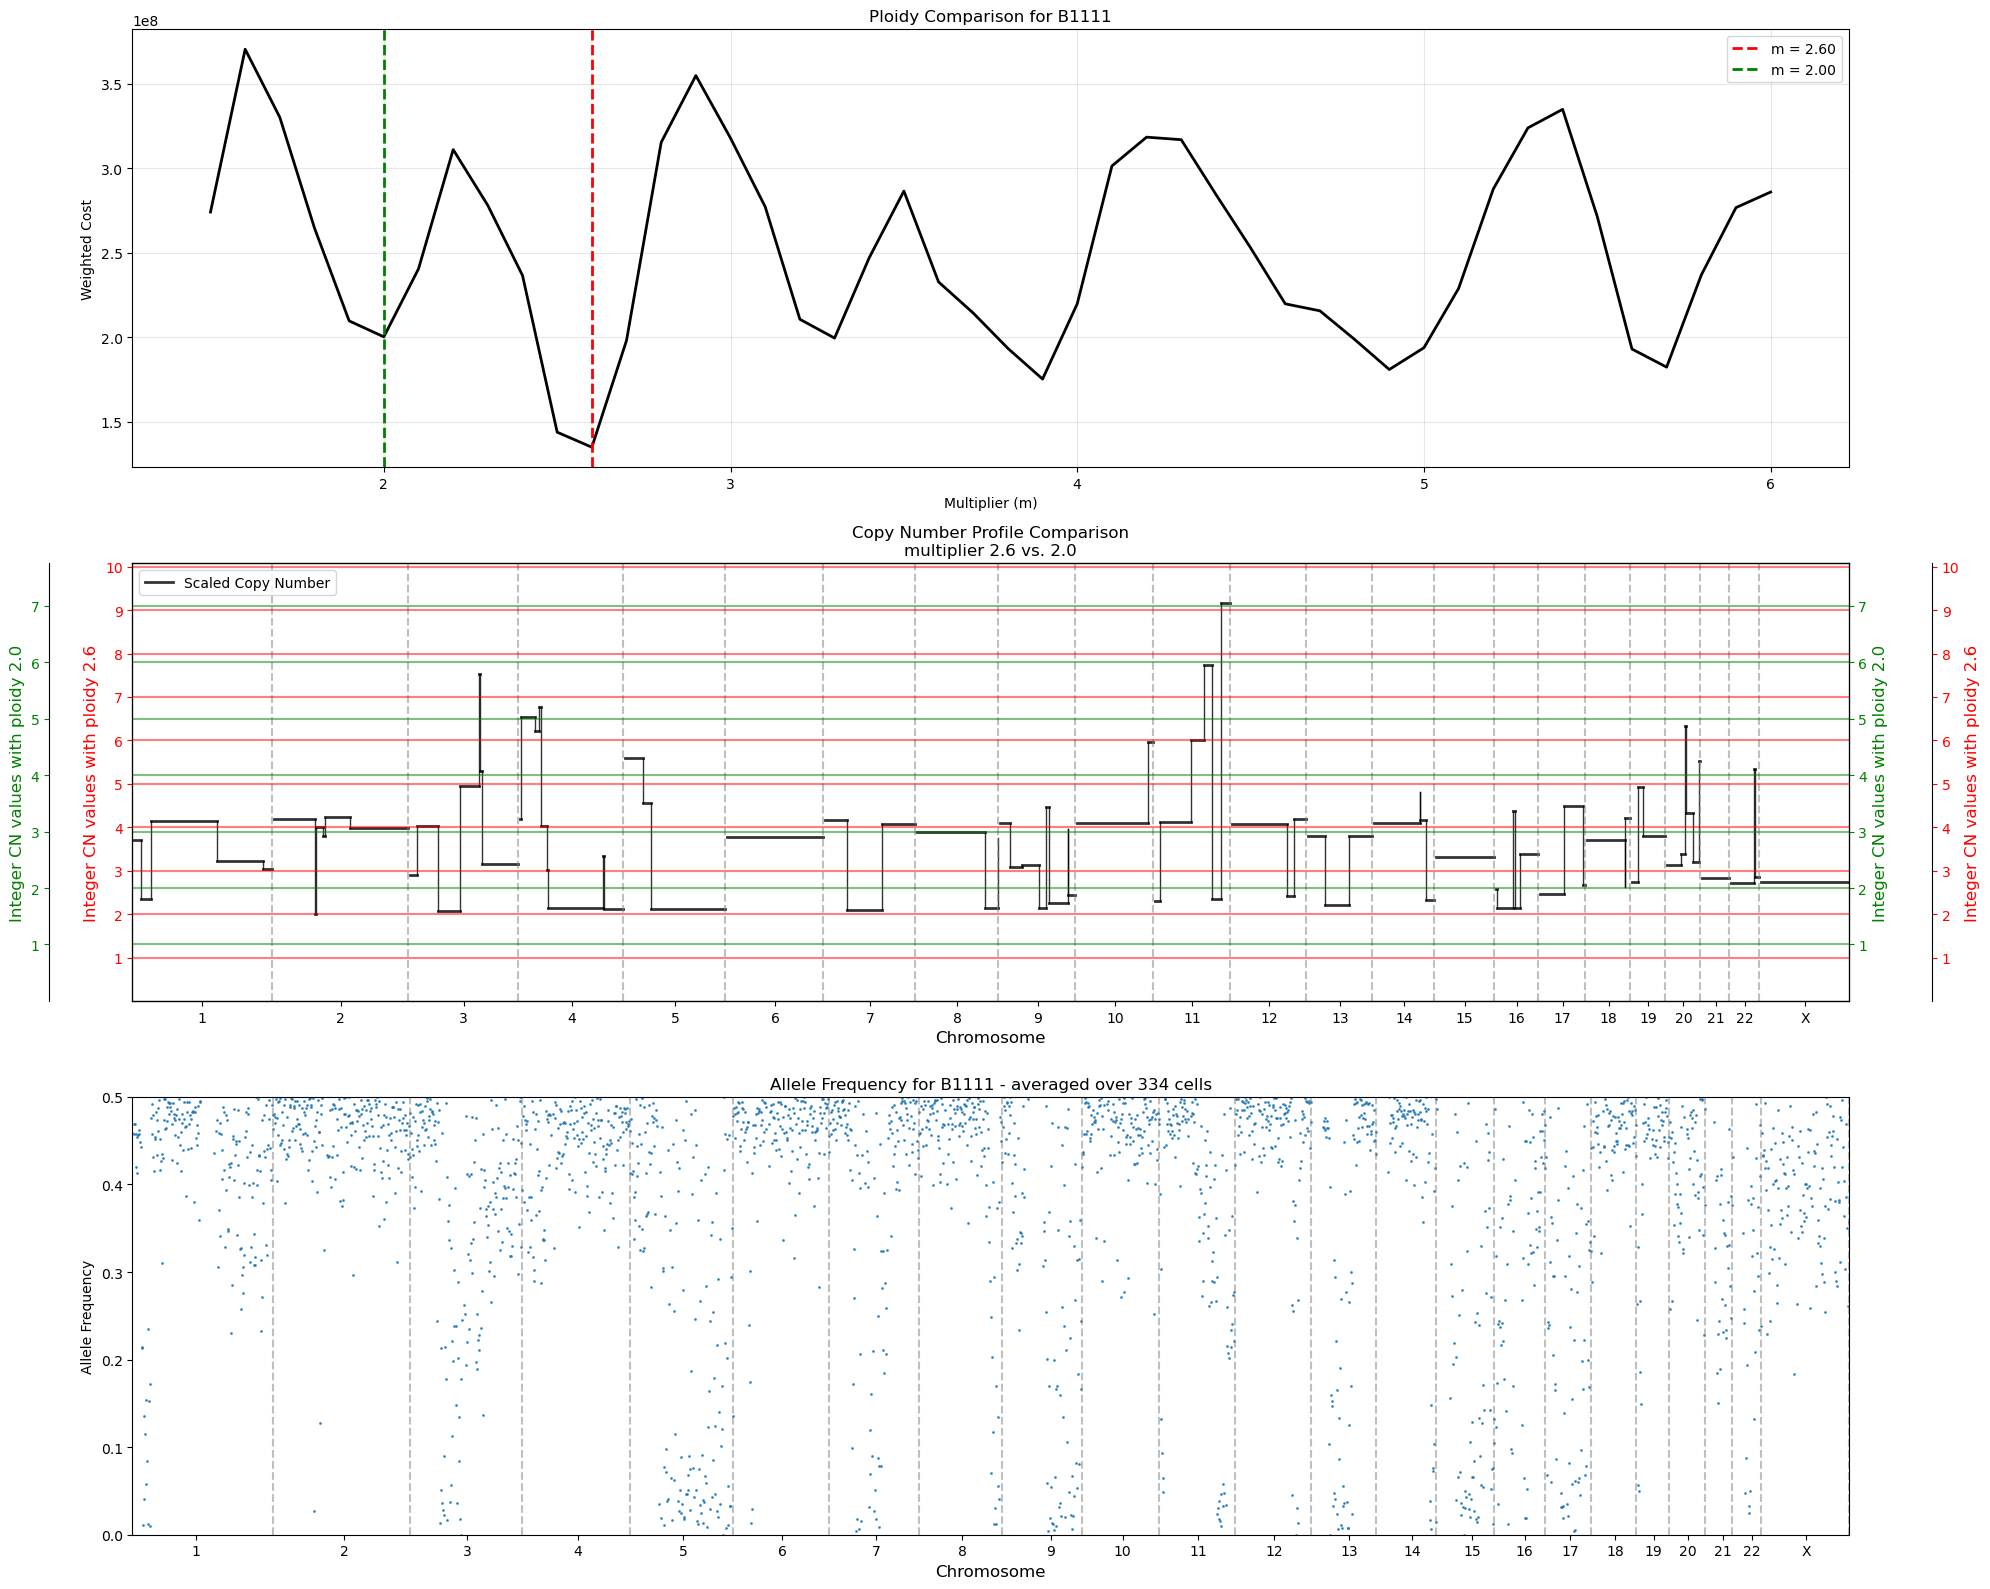

Compared 2.60 vs 2.00 for B1111

Creating ploidy comparison for population: B11121


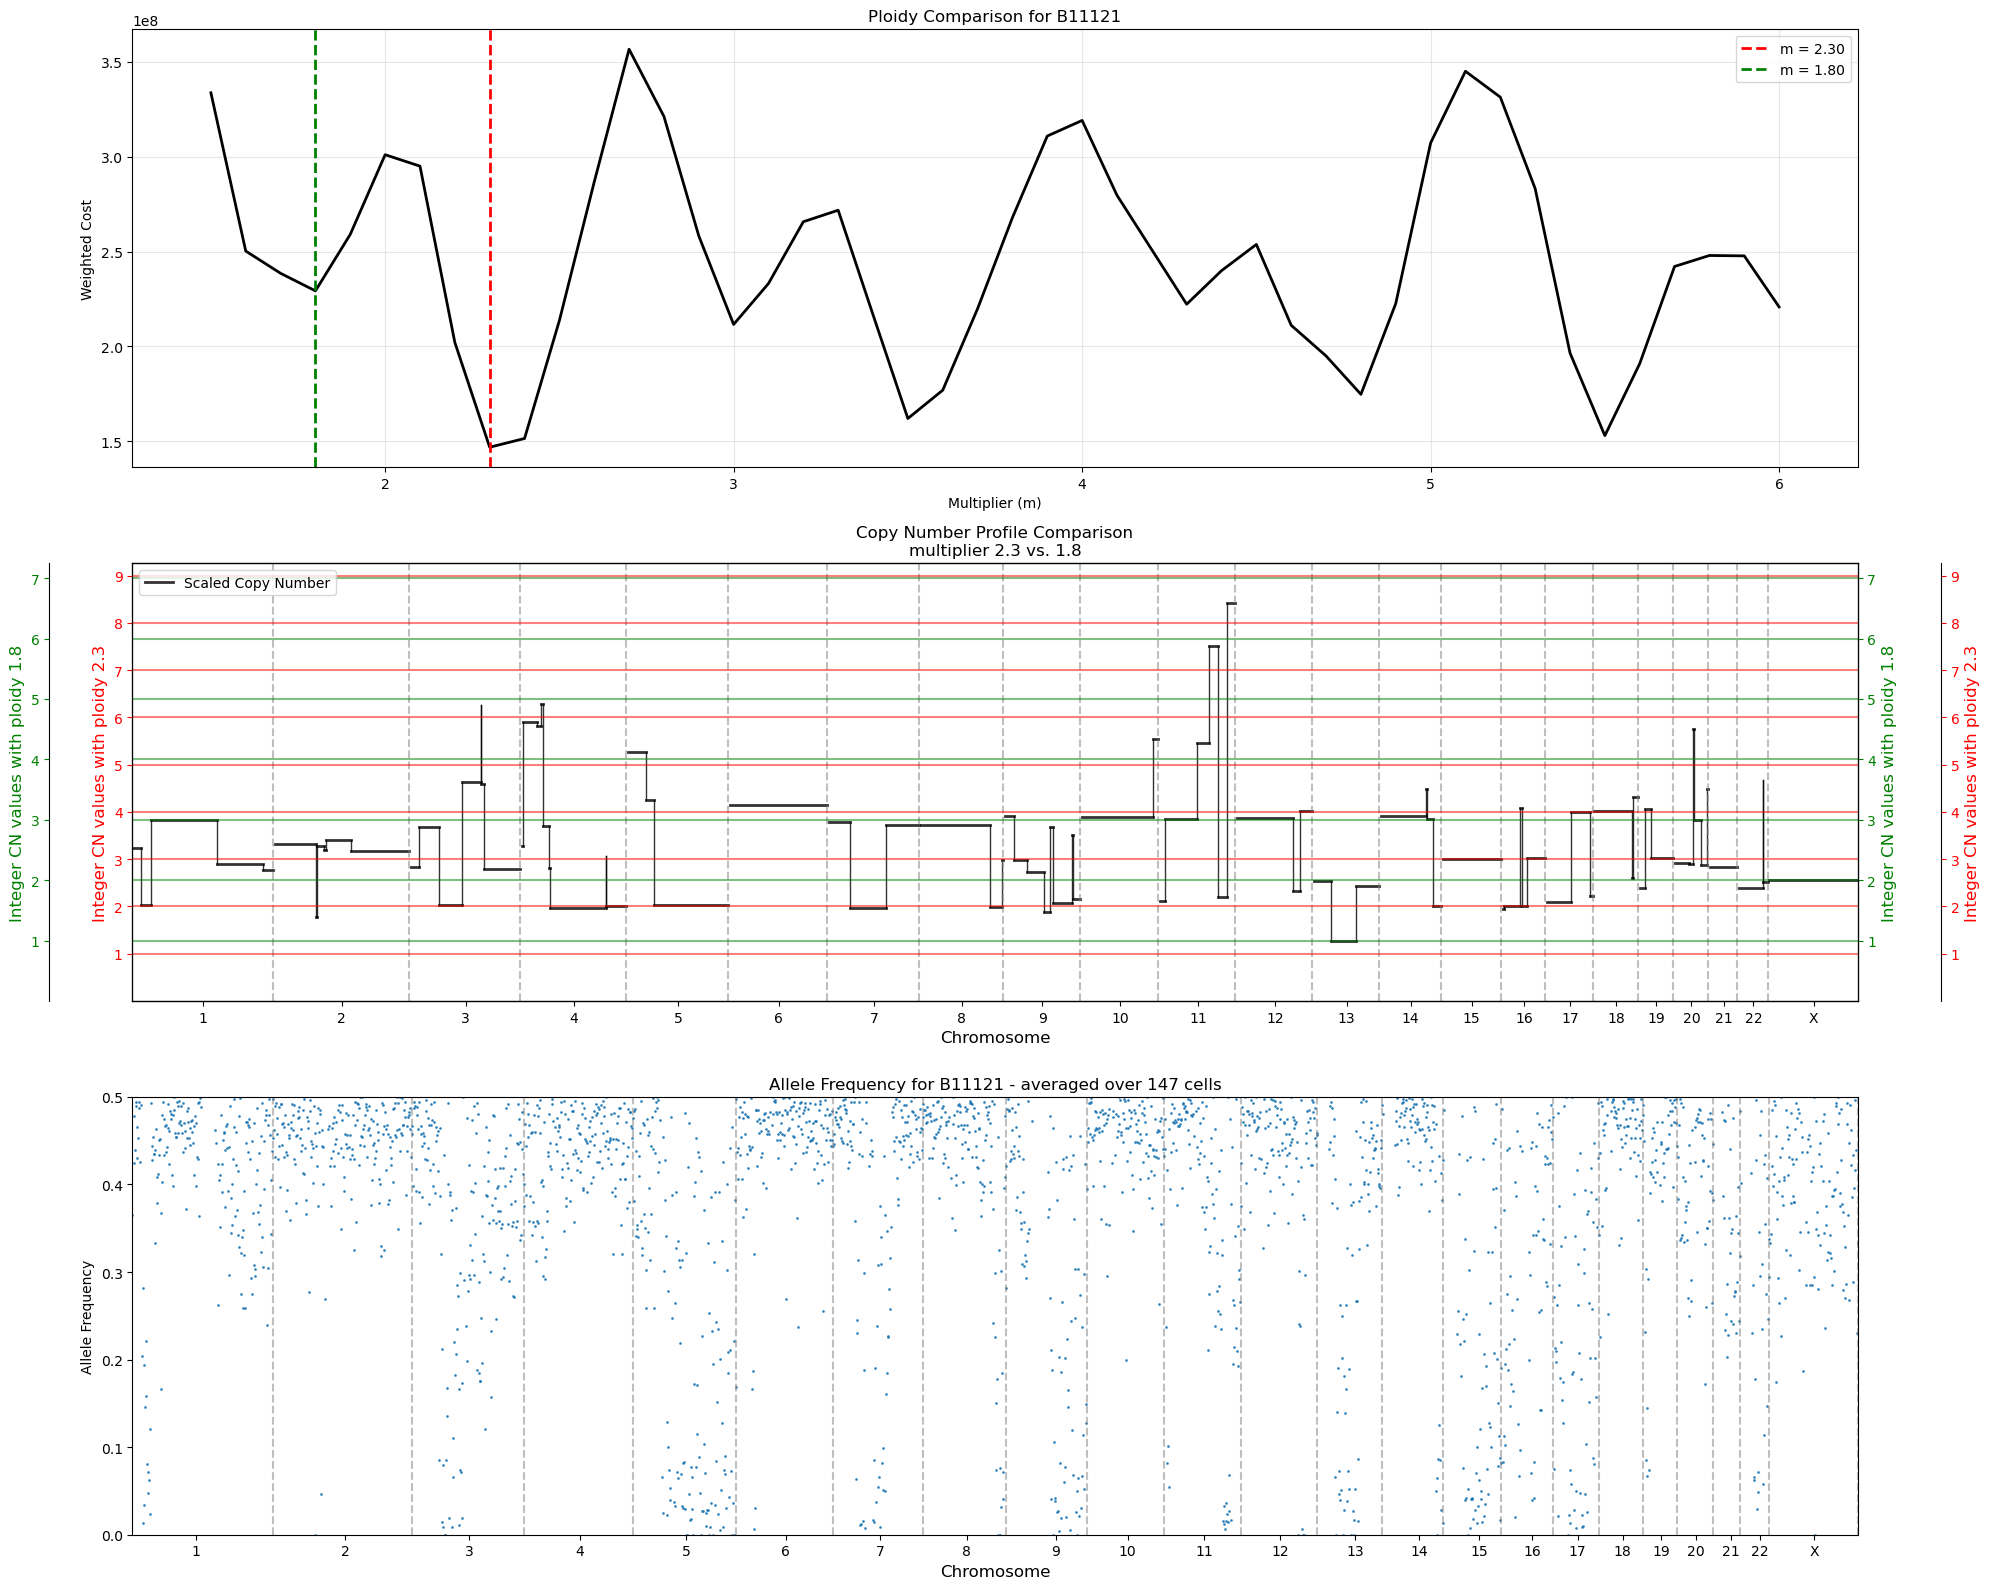

Compared 2.30 vs 1.80 for B11121

Creating ploidy comparison for population: B11122


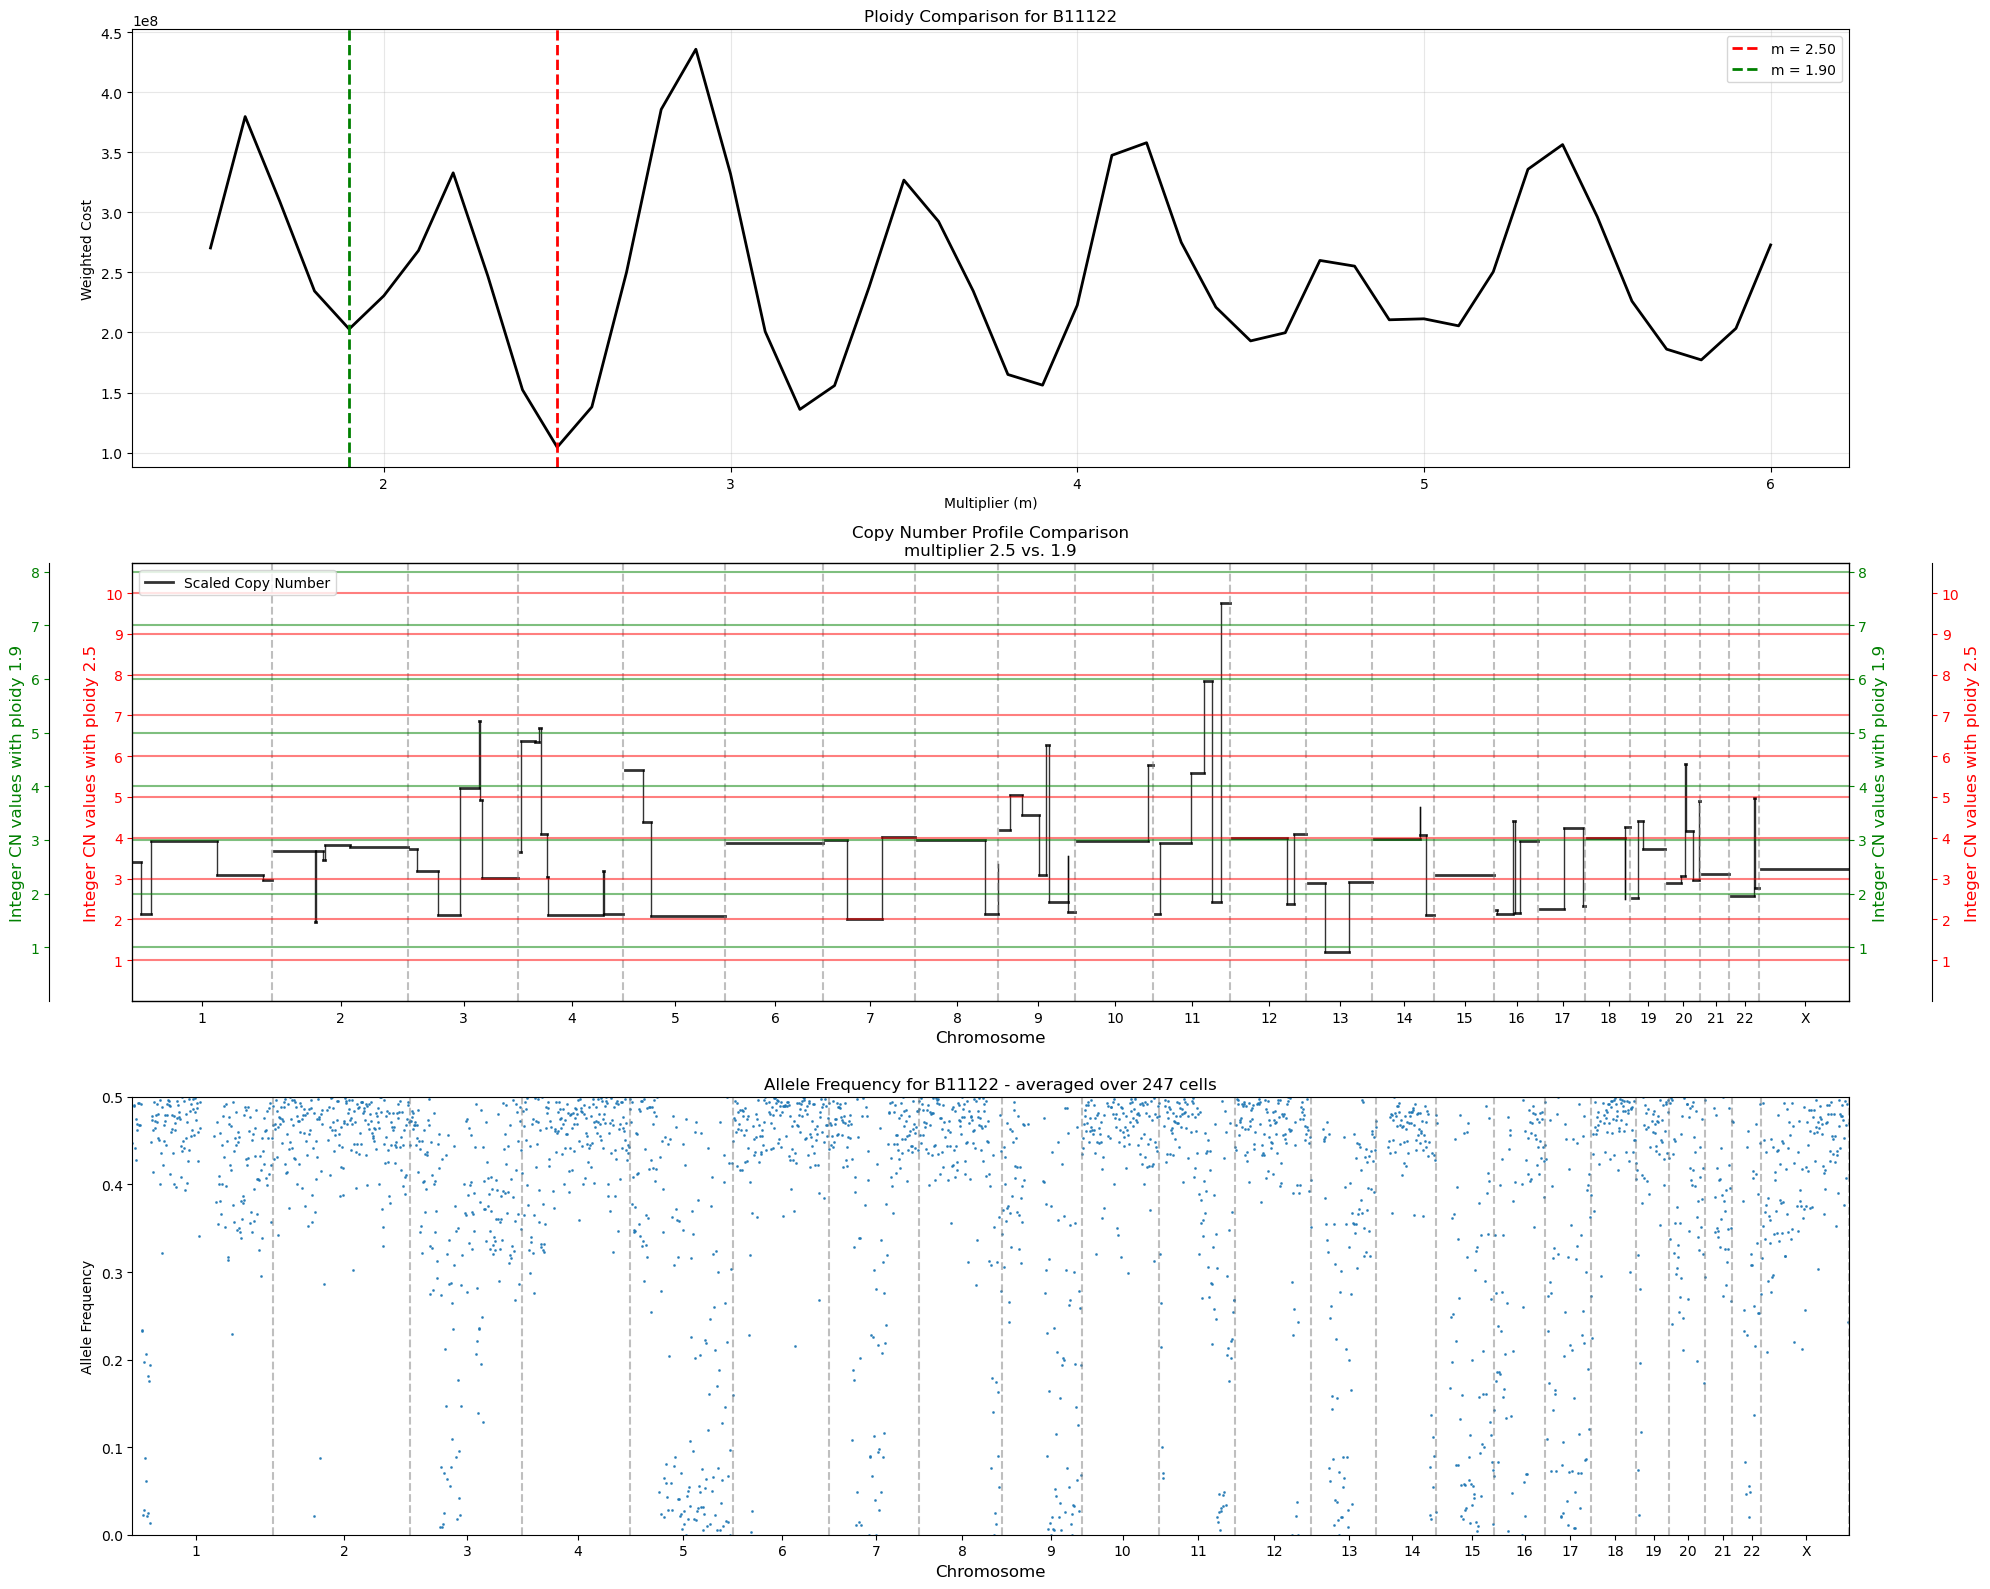

Compared 2.50 vs 1.90 for B11122

Creating ploidy comparison for population: B112


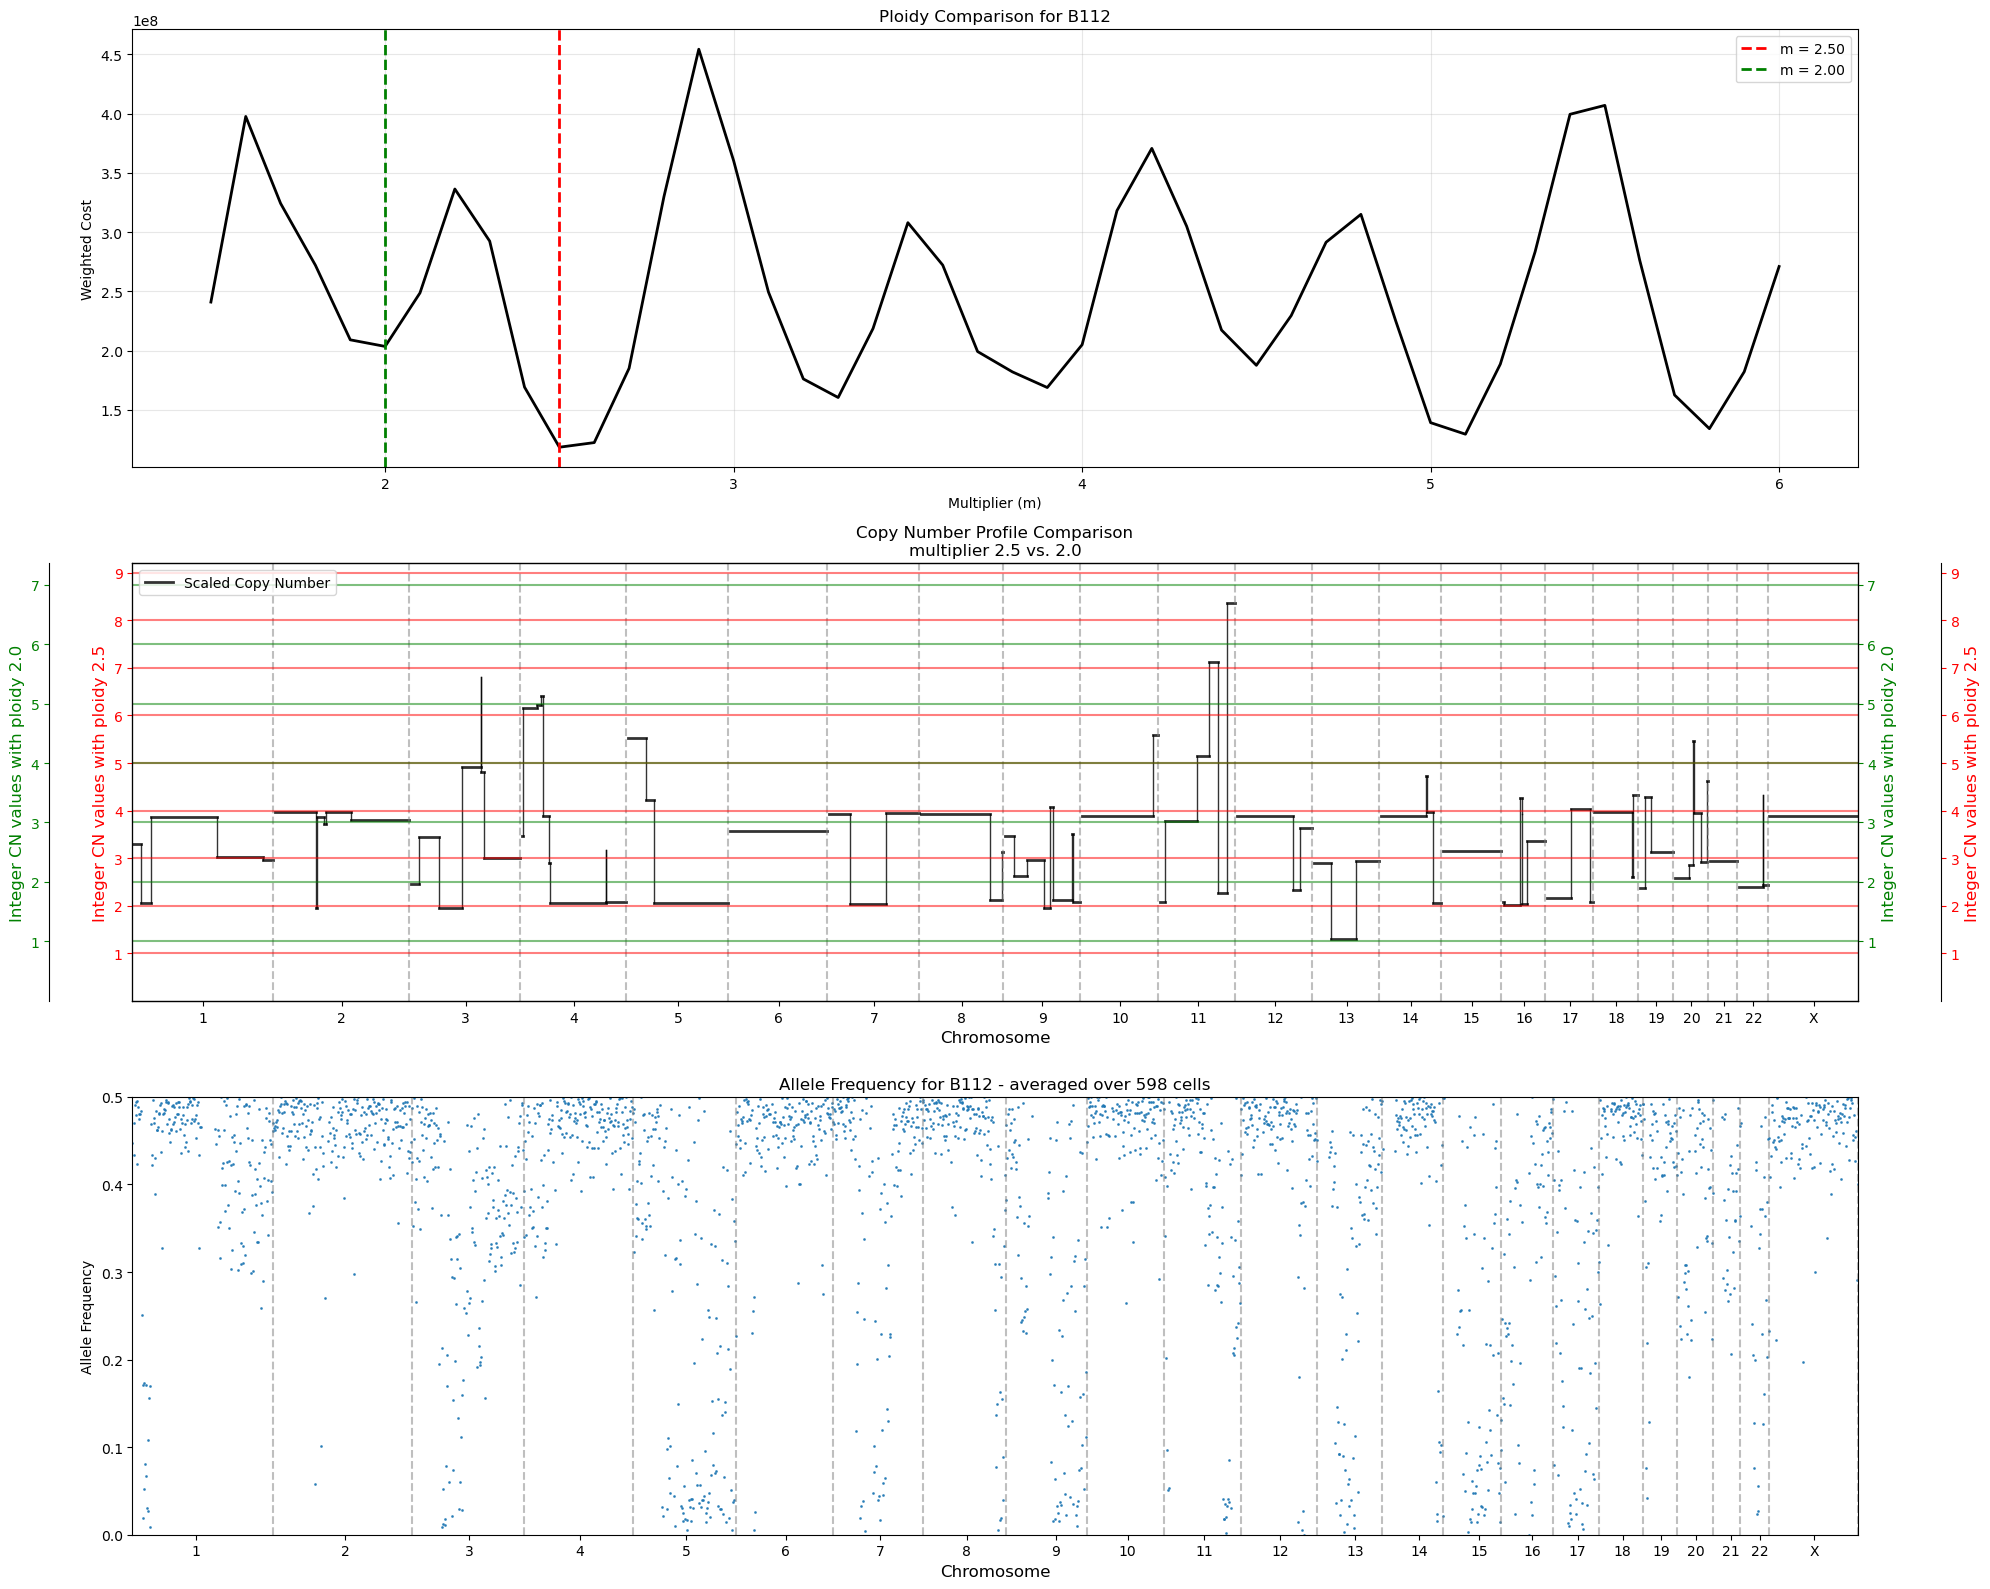

Compared 2.50 vs 2.00 for B112

Creating ploidy comparison for population: B12


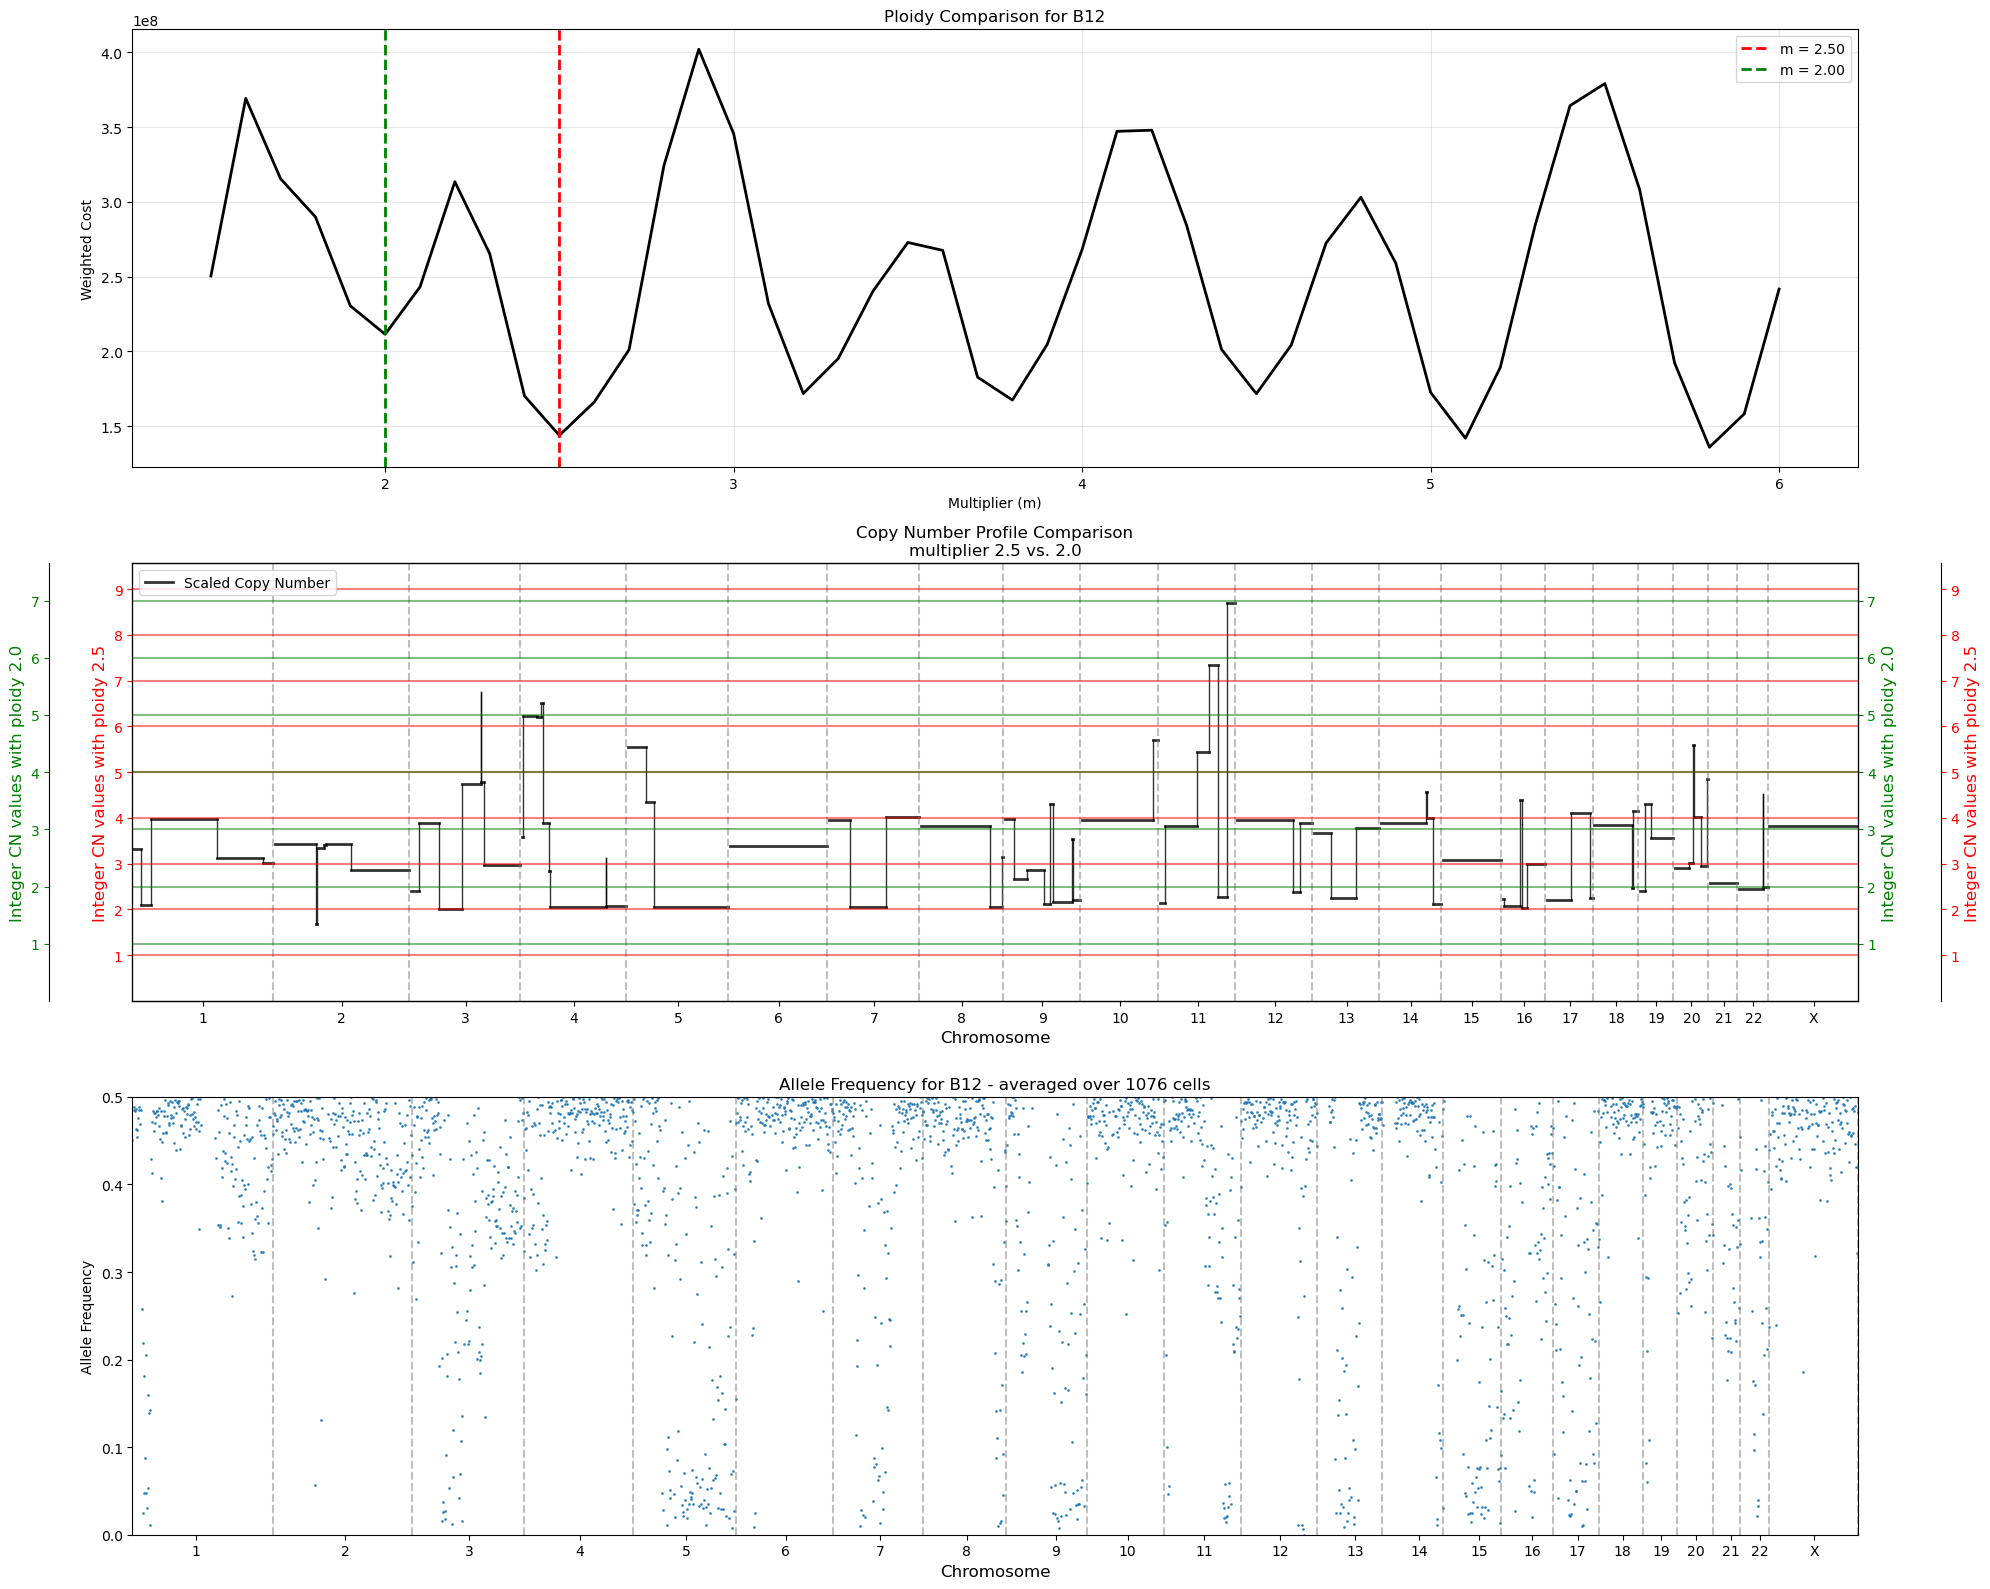

Compared 2.50 vs 2.00 for B12


In [104]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to ploidy 2 (that's not the global minimum)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Pick the one closest to 2.0
        second_best_m = min(other_minima, key=lambda x: abs(x - 2.0))
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")


Creating ploidy comparison for population: B1111


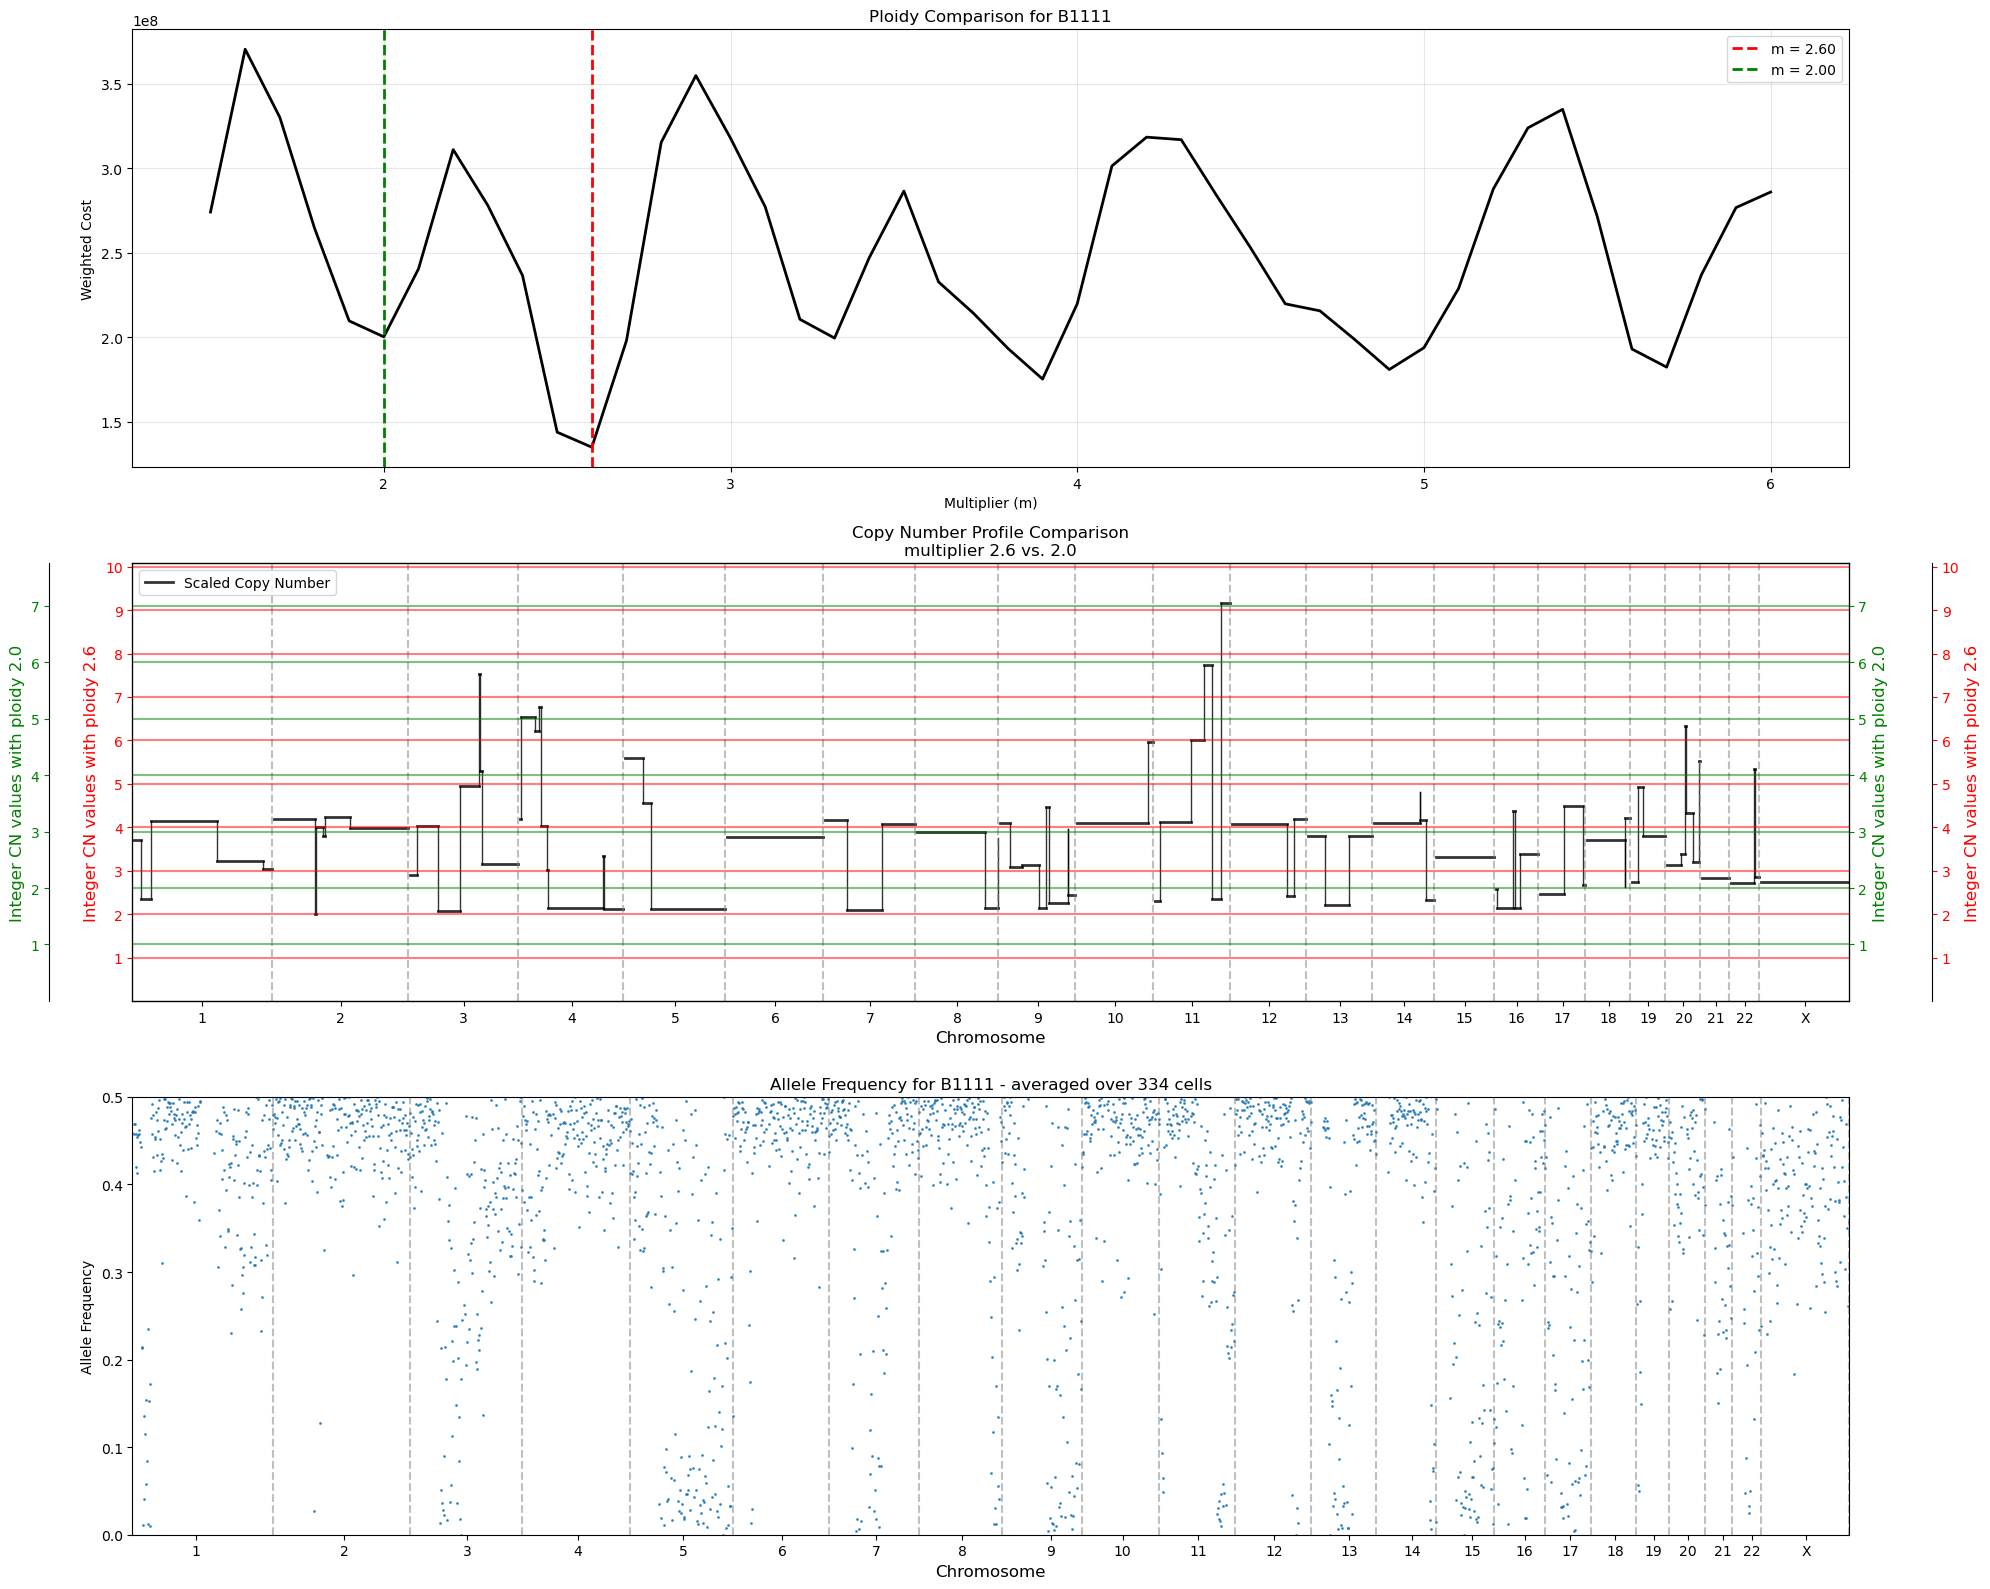

Compared 2.60 vs 2.00 for B1111

Creating ploidy comparison for population: B11121


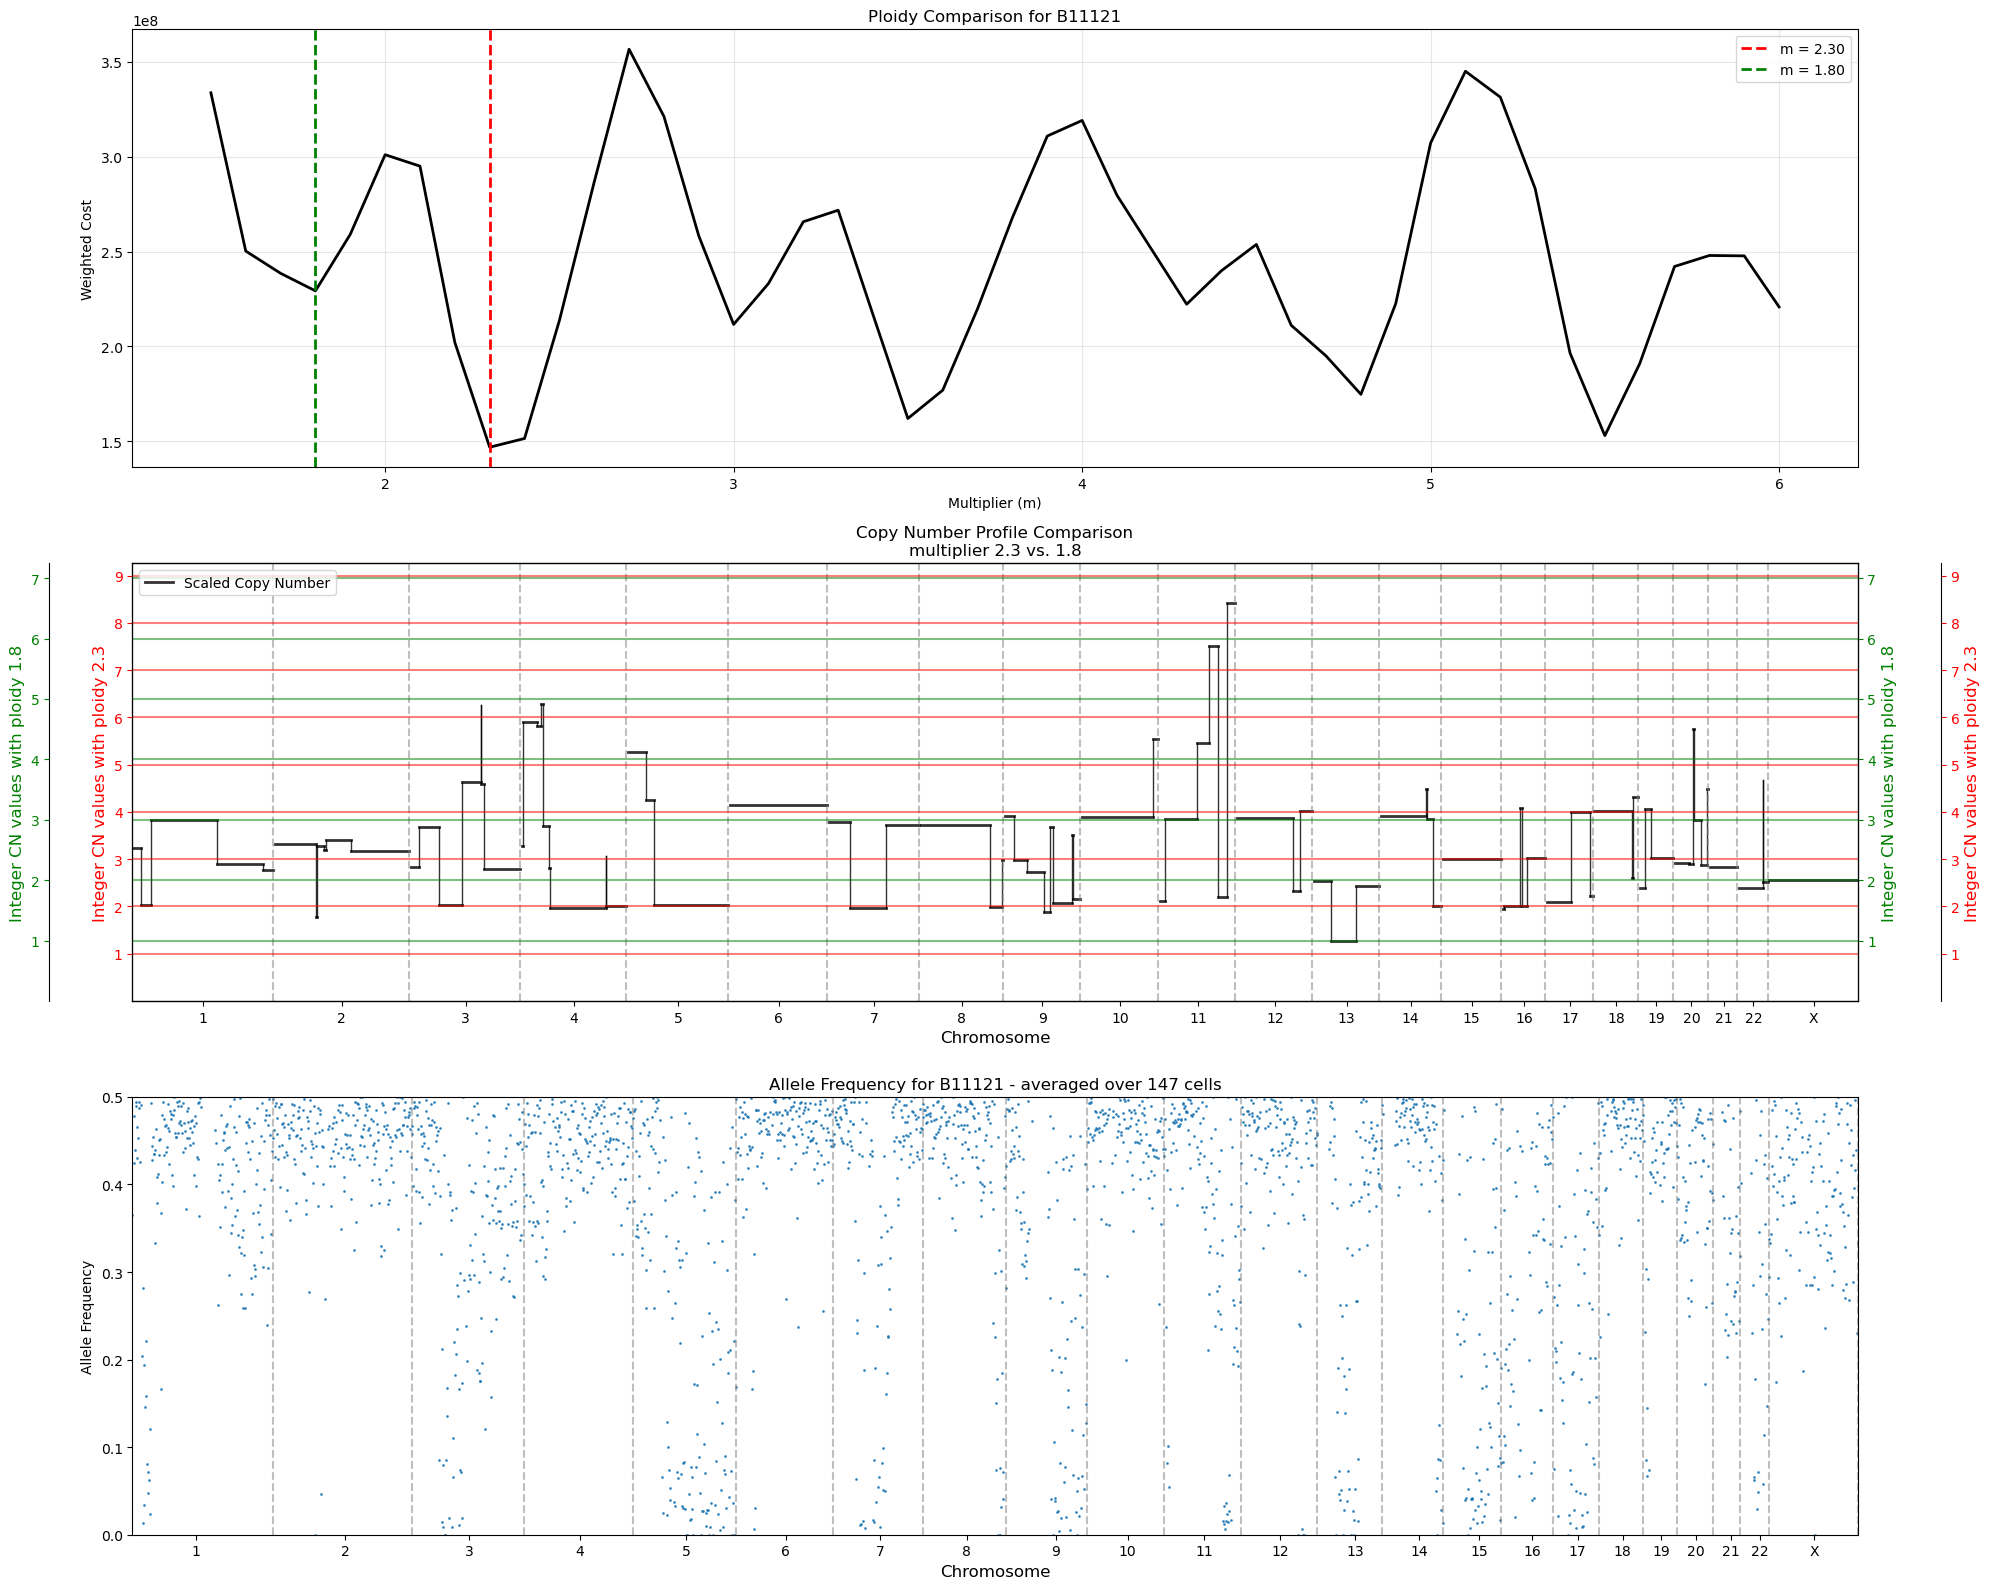

Compared 2.30 vs 1.80 for B11121

Creating ploidy comparison for population: B11122


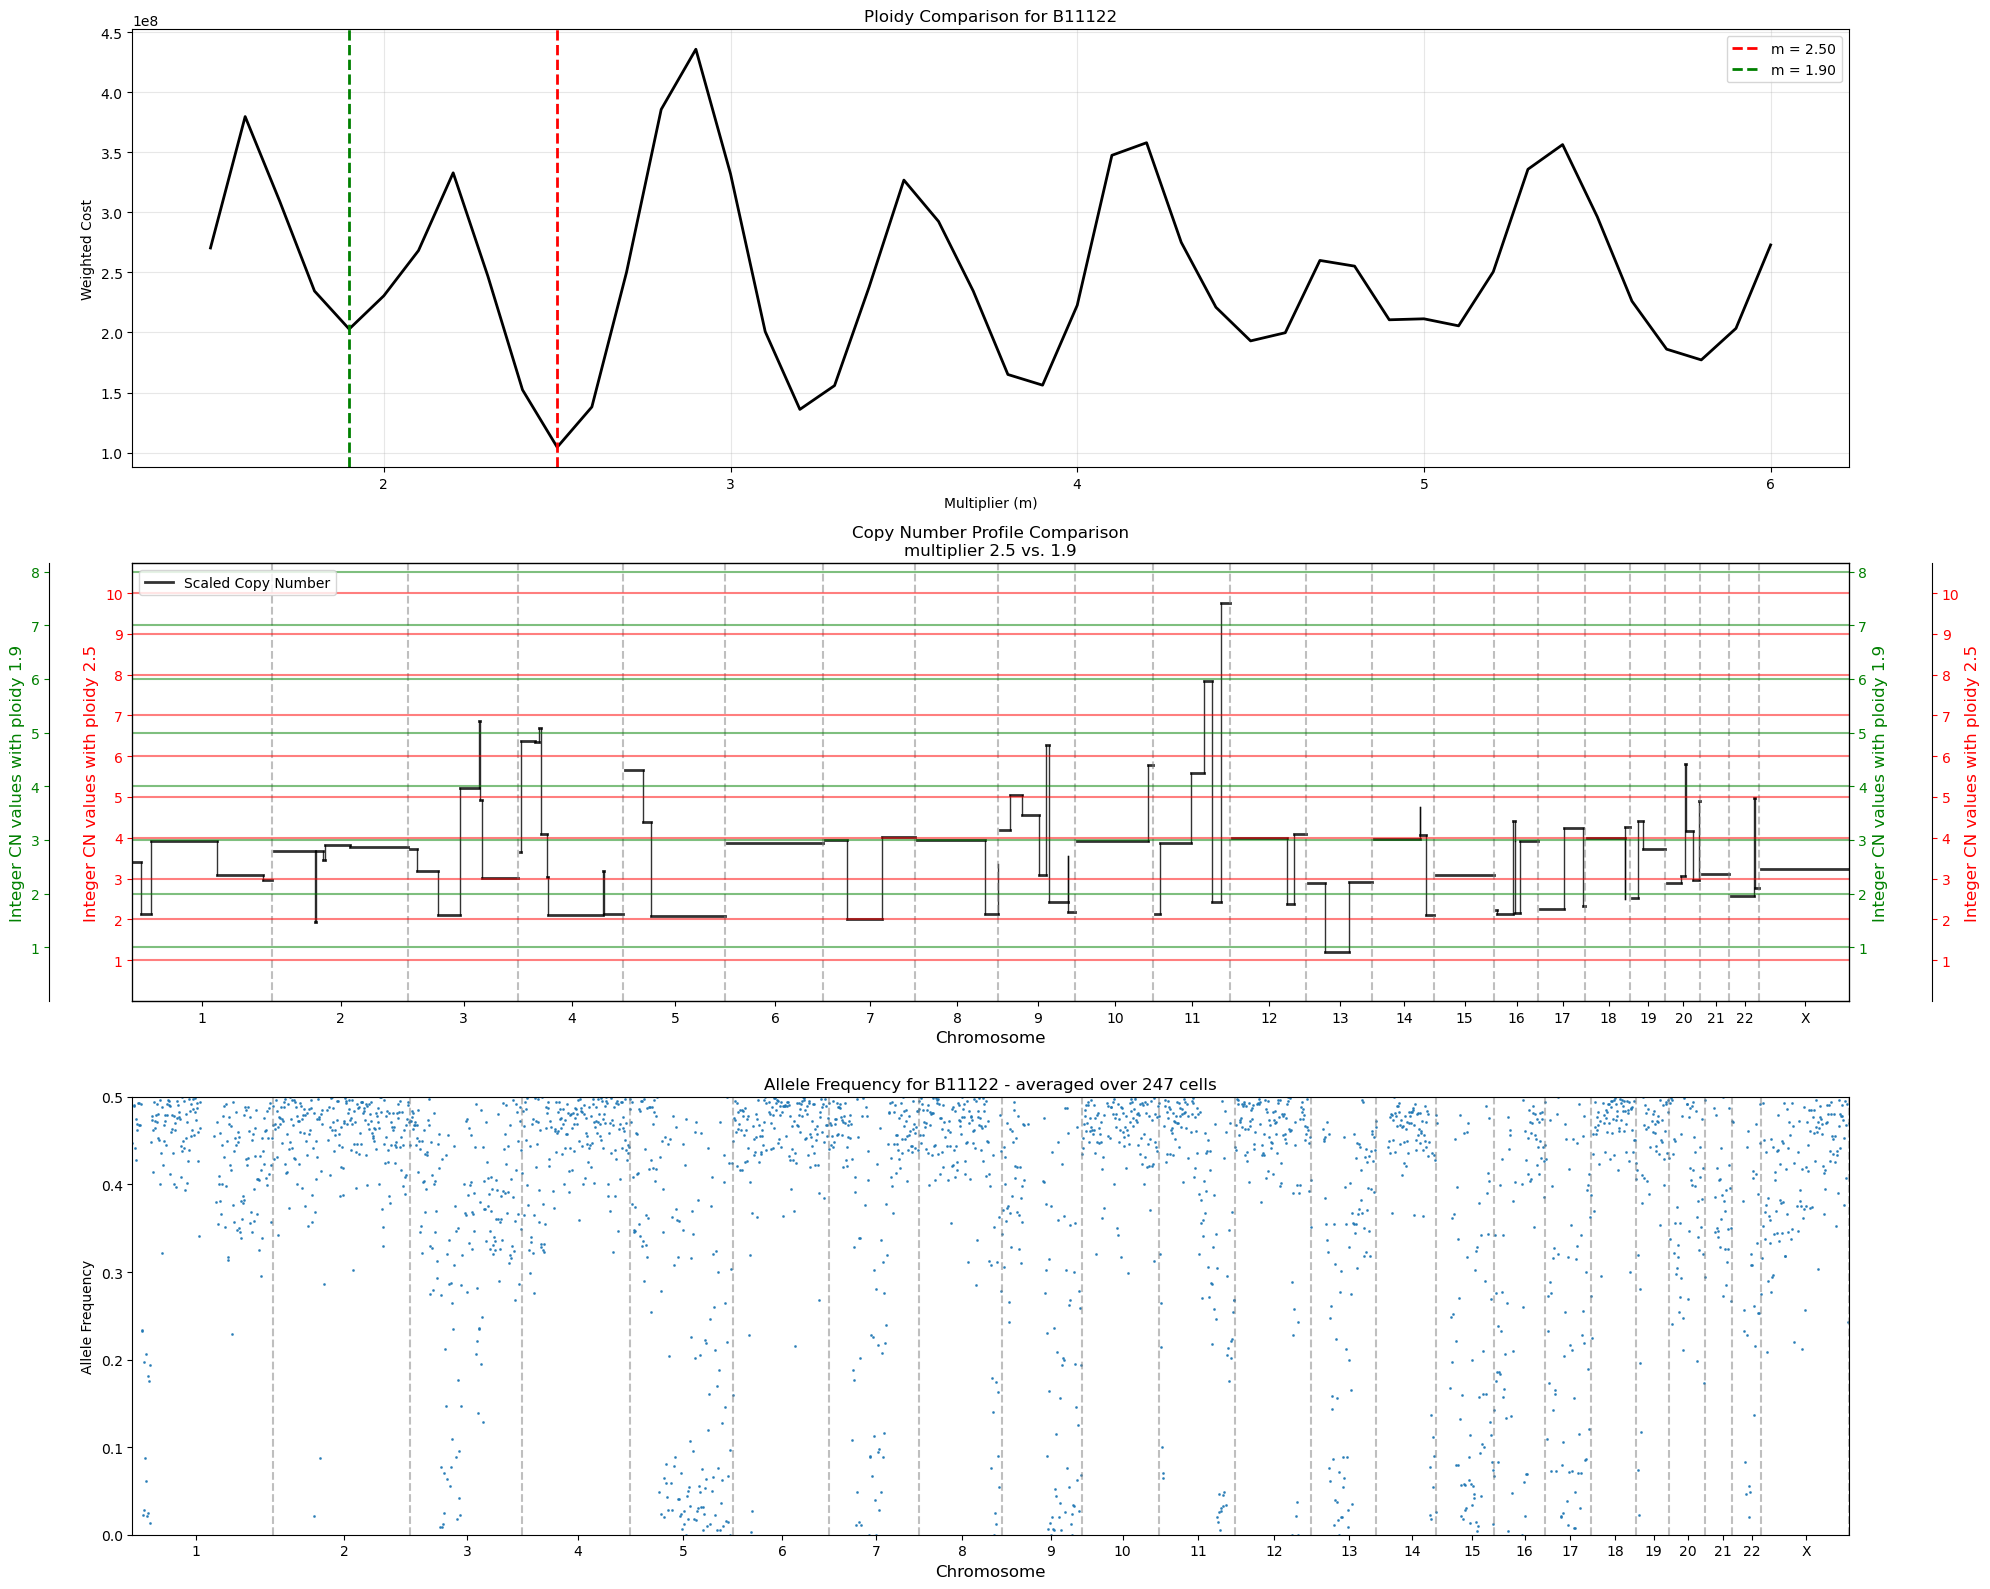

Compared 2.50 vs 1.90 for B11122

Creating ploidy comparison for population: B112


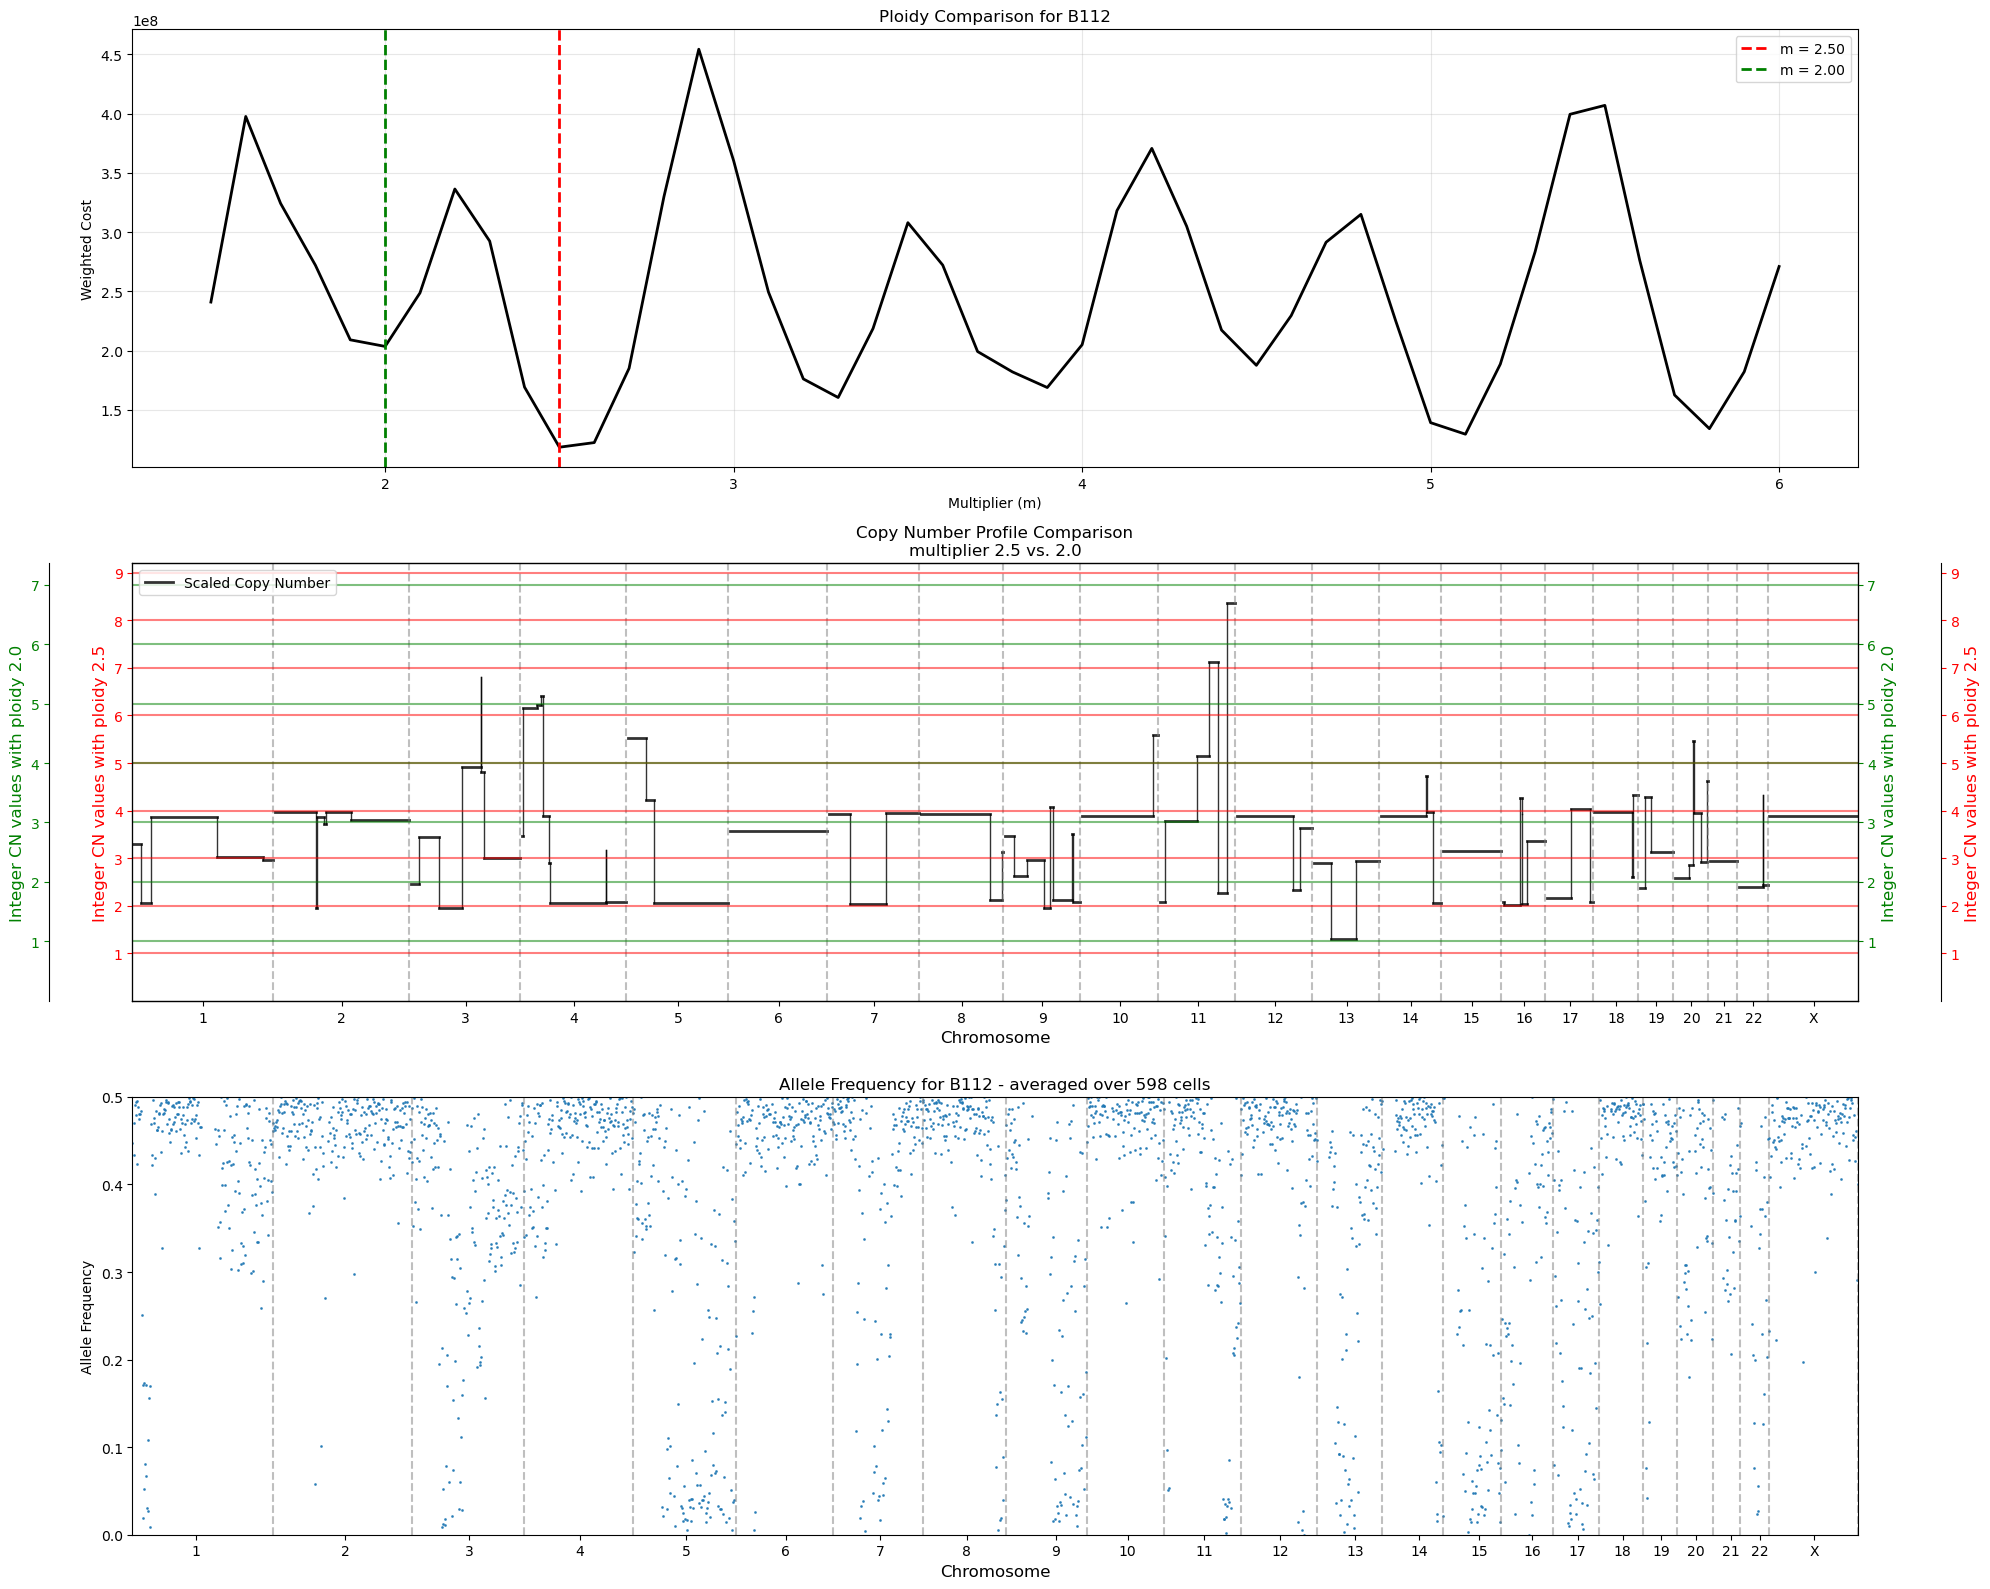

Compared 2.50 vs 2.00 for B112

Creating ploidy comparison for population: B12


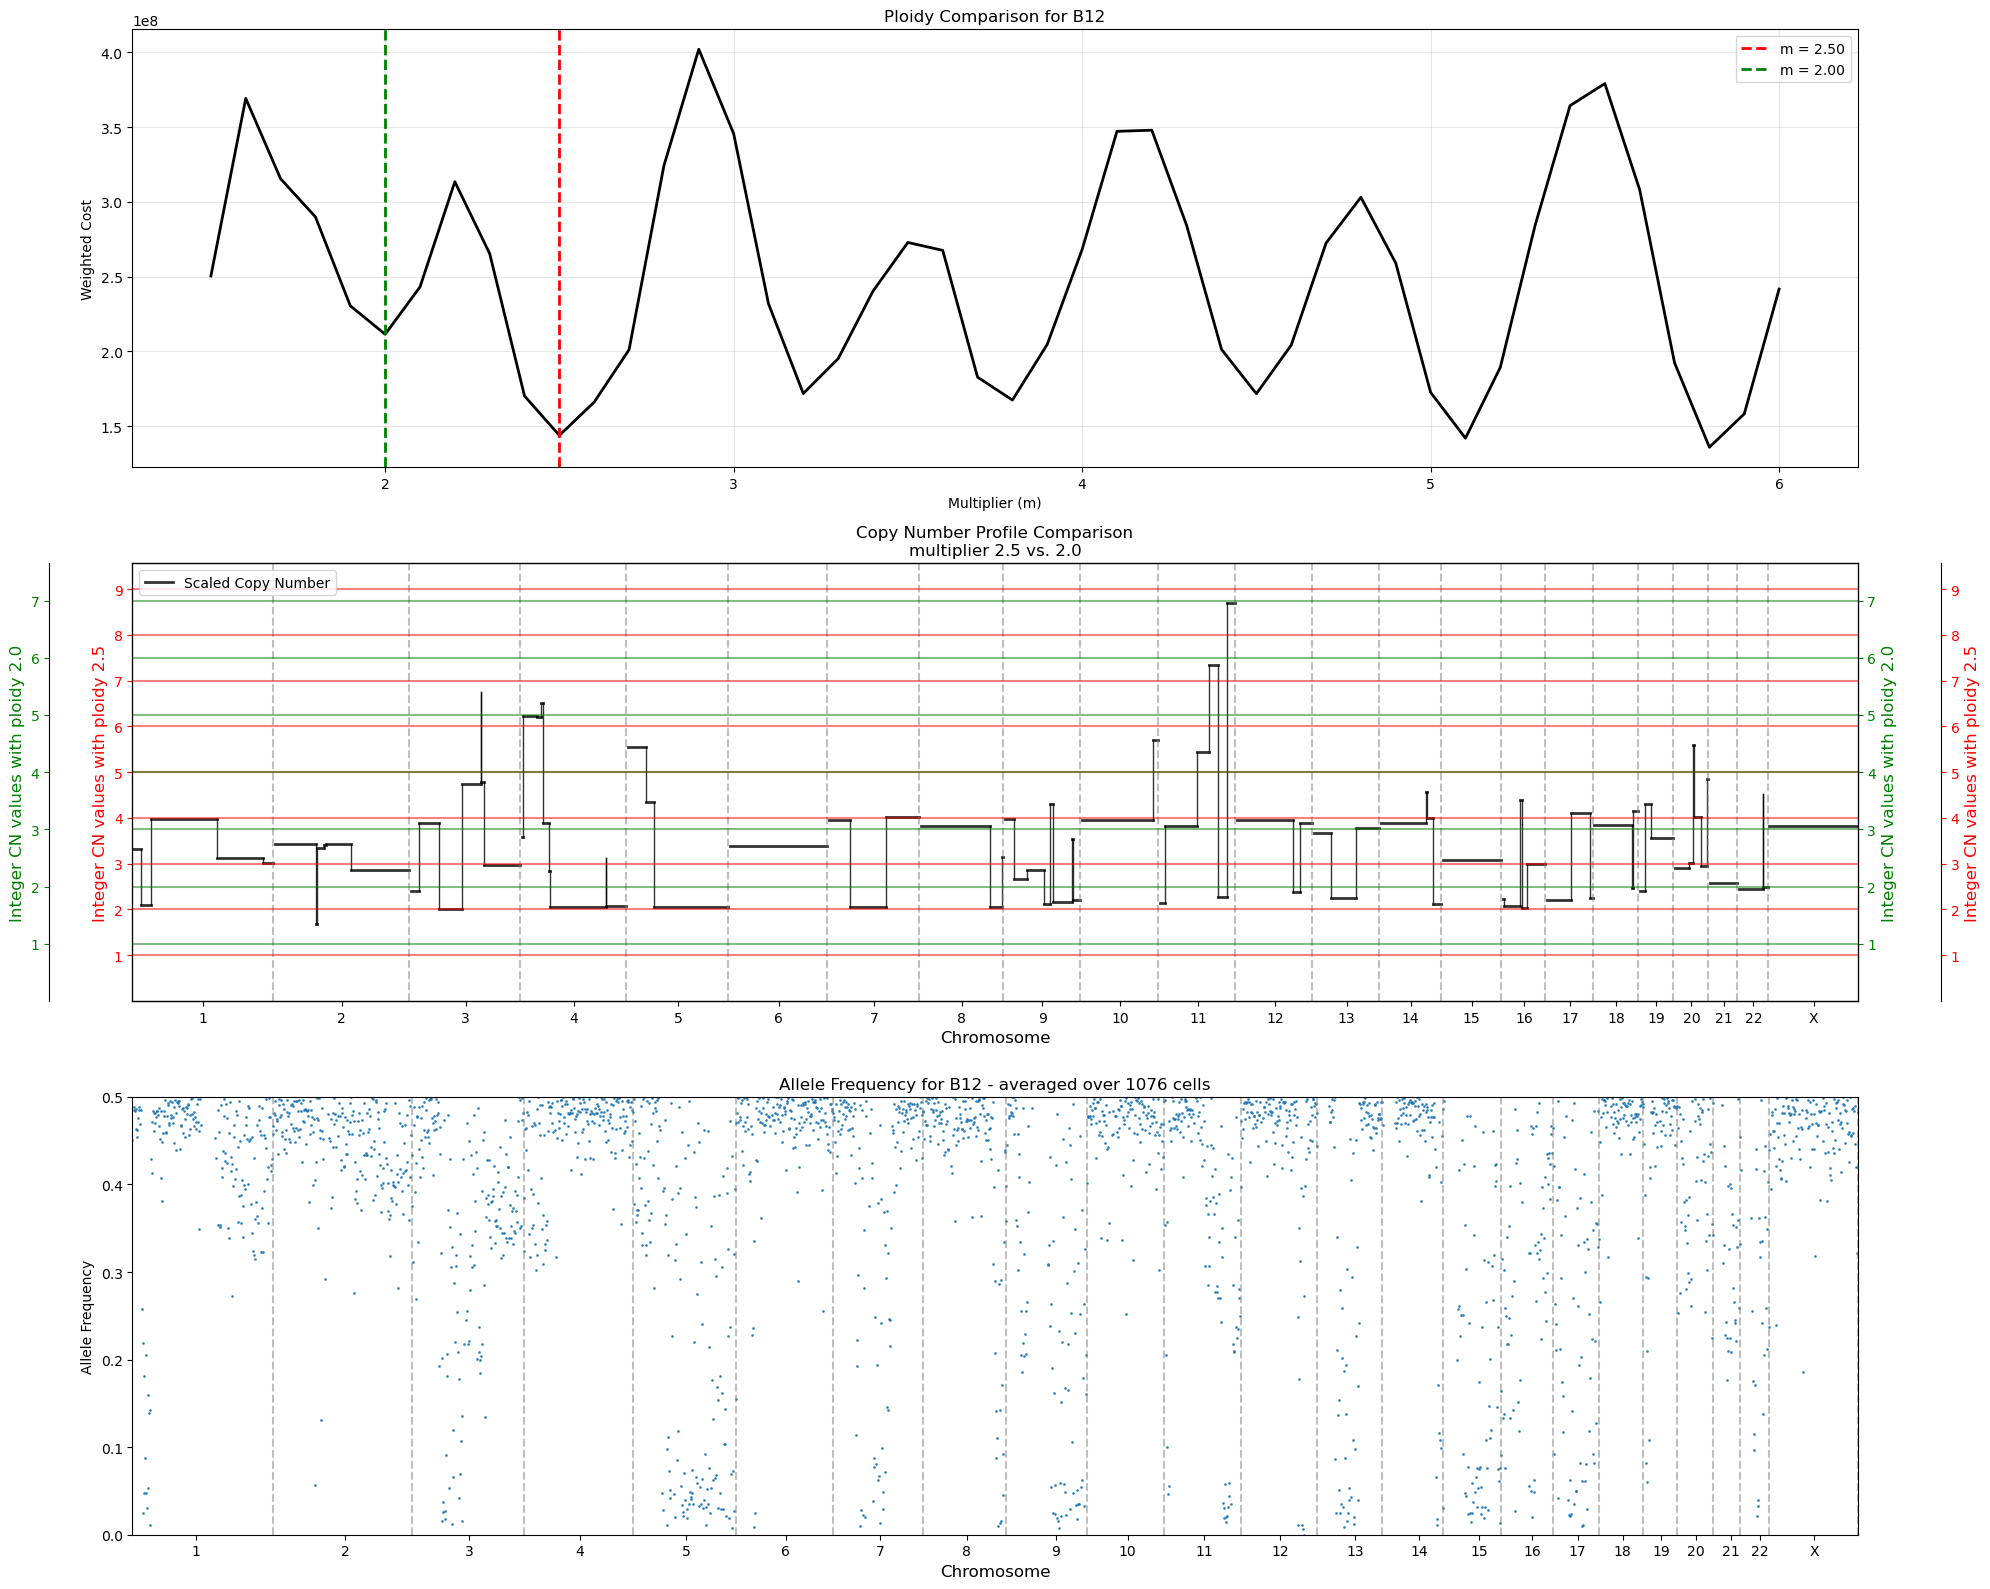

Compared 2.50 vs 2.00 for B12


In [105]:
# Loop through all populations and create ploidy comparison plots
for pop_name in ploidy_results_A.keys():
    print(f"\n{'='*60}")
    print(f"Creating ploidy comparison for population: {pop_name}")
    
    results = ploidy_results_A[pop_name]
    local_minima = results['local_minima']
    optimal_m = results['optimal_multiplier']
    
    # Find the local minimum closest to the global minimum (excluding the global minimum itself)
    other_minima = [m for m, _ in local_minima if m != optimal_m]
    
    if other_minima:
        # Find the minimum distance to the global minimum
        min_distance = min(abs(m - optimal_m) for m in other_minima)
        # Get all minima at this minimum distance
        closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
        # Pick the smaller one if there are ties
        second_best_m = min(closest_minima)
    else:
        print(f"Only one minimum found for {pop_name}, skipping comparison")
        continue
    
    plot_ploidy_comparison(
        results_df=profile_dfs_A[pop_name],
        cost_results=results['cost_results'],
        optimal_m=optimal_m,
        local_m=second_best_m,
        pop_col=f'{pop_name}_ratio',
        hap_count_df=hap_count_df,
        cells=A_dict[pop_name]['cells']
    )
    
    print(f"Compared {optimal_m:.2f} vs {second_best_m:.2f} for {pop_name}")

In [106]:
# # reorder A_dict based on new order from overlap_df index
# A_dict_reordered = {k: A_dict[k] for k in overlap_df.index}

In [107]:
# Add to your imports at the top:



In [108]:
# Create population summary table
summary_rows = []

for pop_name in A_dict.keys():
    # Get cells for this population
    pop_cells = A_dict[pop_name]['cells']
    num_cells = len(pop_cells)
    
        

    # Calculate average read count per cell for this population
    pop_data = all_data[pop_cells]
    avg_read_count = pop_data.sum().sum() / num_cells
    
    # Get relative counts (already computed in relative_counts_A)
    relative_count = relative_counts_A[pop_name].mean()

    if pop_name!= normal_A:
        results = ploidy_results_A[pop_name]
        local_minima = results['local_minima']
        target_m = 2 * relative_count
        #pick two best minima
        optimal_m = results['optimal_multiplier']
    
        # Find the local minimum closest to the global minimum (excluding the global minimum itself)
        other_minima = [m for m, _ in local_minima if m != optimal_m]
        
        if other_minima:
            # Find the minimum distance to the global minimum
            min_distance = min(abs(m - optimal_m) for m in other_minima)
            # Get all minima at this minimum distance
            closest_minima = [m for m in other_minima if abs(m - optimal_m) == min_distance]
            # Pick the smaller one if there are ties
            second_best_m = min(closest_minima)
    # Get relative ploidy from ploidy_results_A (if it exists, otherwise it's the normal so use 1.0)
    if pop_name in ploidy_results_A:
        relative_ploidy = optimal_m
    else:
        relative_ploidy = 2.0  # Normal population
        second_best_m = 2.0
    
    # Add (normal) label if this is the normal population
    display_name = f"{pop_name} (normal)" if pop_name == normal_A else pop_name
    
    summary_rows.append({
        'pop_name': display_name,
        'num_cells': num_cells,
        'avg_read_count_per_cell': avg_read_count,
        'relative_counts': relative_count,
        'best_ploidy': relative_ploidy,
        'second_best' : second_best_m
    })

# Create DataFrame
population_summary_table = pd.DataFrame(summary_rows)

population_summary_table["rel_counts*2"] = population_summary_table["relative_counts"] * 2
#display it nicely
population_summary_table

,pop_name,num_cells,avg_read_count_per_cell,relative_counts,best_ploidy,second_best,rel_counts*2
0,B1111,334,25531.134731,1.367542,2.6,2.0,2.735084
1,B11121,147,26522.959184,1.420668,2.3,1.8,2.841336
2,B11122,247,26144.380567,1.400390,2.5,1.9,2.800779
3,B112,598,25447.892977,1.363083,2.5,2.0,2.726167
4,B12,1076,25294.852230,1.354886,2.5,2.0,2.709772
5,B2 (normal),122,18669.360656,1.000000,2.0,2.0,2.000000


In [109]:
population_summary_table.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

=== Creating Copy Number Heatmaps ===
Processing 90 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Heatmap A matrix dimensions: 90 segments × 2524 cells
Expanding heatmap from 90 segments to 5369 rows...

Chromosome representation in heatmap:
chr1: 448 rows, 246,107,906 bp total
chr2: 429 rows, 236,348,678 bp total
chr3: 347 rows, 190,893,744 bp total
chr4: 333 rows, 182,809,071 bp total
chr5: 320 rows, 175,971,707 bp total
chr6: 310 rows, 170,376,978 bp total
chr7: 287 rows, 157,399,127 bp total
chr8: 262 rows, 144,604,995 bp total
chr9: 240 rows, 131,862,003 bp total
chr10: 244 rows, 134,331,444 bp total
chr11: 239 rows, 131,569,776 bp total
chr12: 240 rows, 131,985,756 bp total
chr13: 205 rows, 113,342,641 bp total
chr14: 191 rows, 105,050,655 bp total
chr15: 185 rows, 101,854,608 bp total
chr16: 136 rows, 75,128,776 bp total
chr17: 144 r

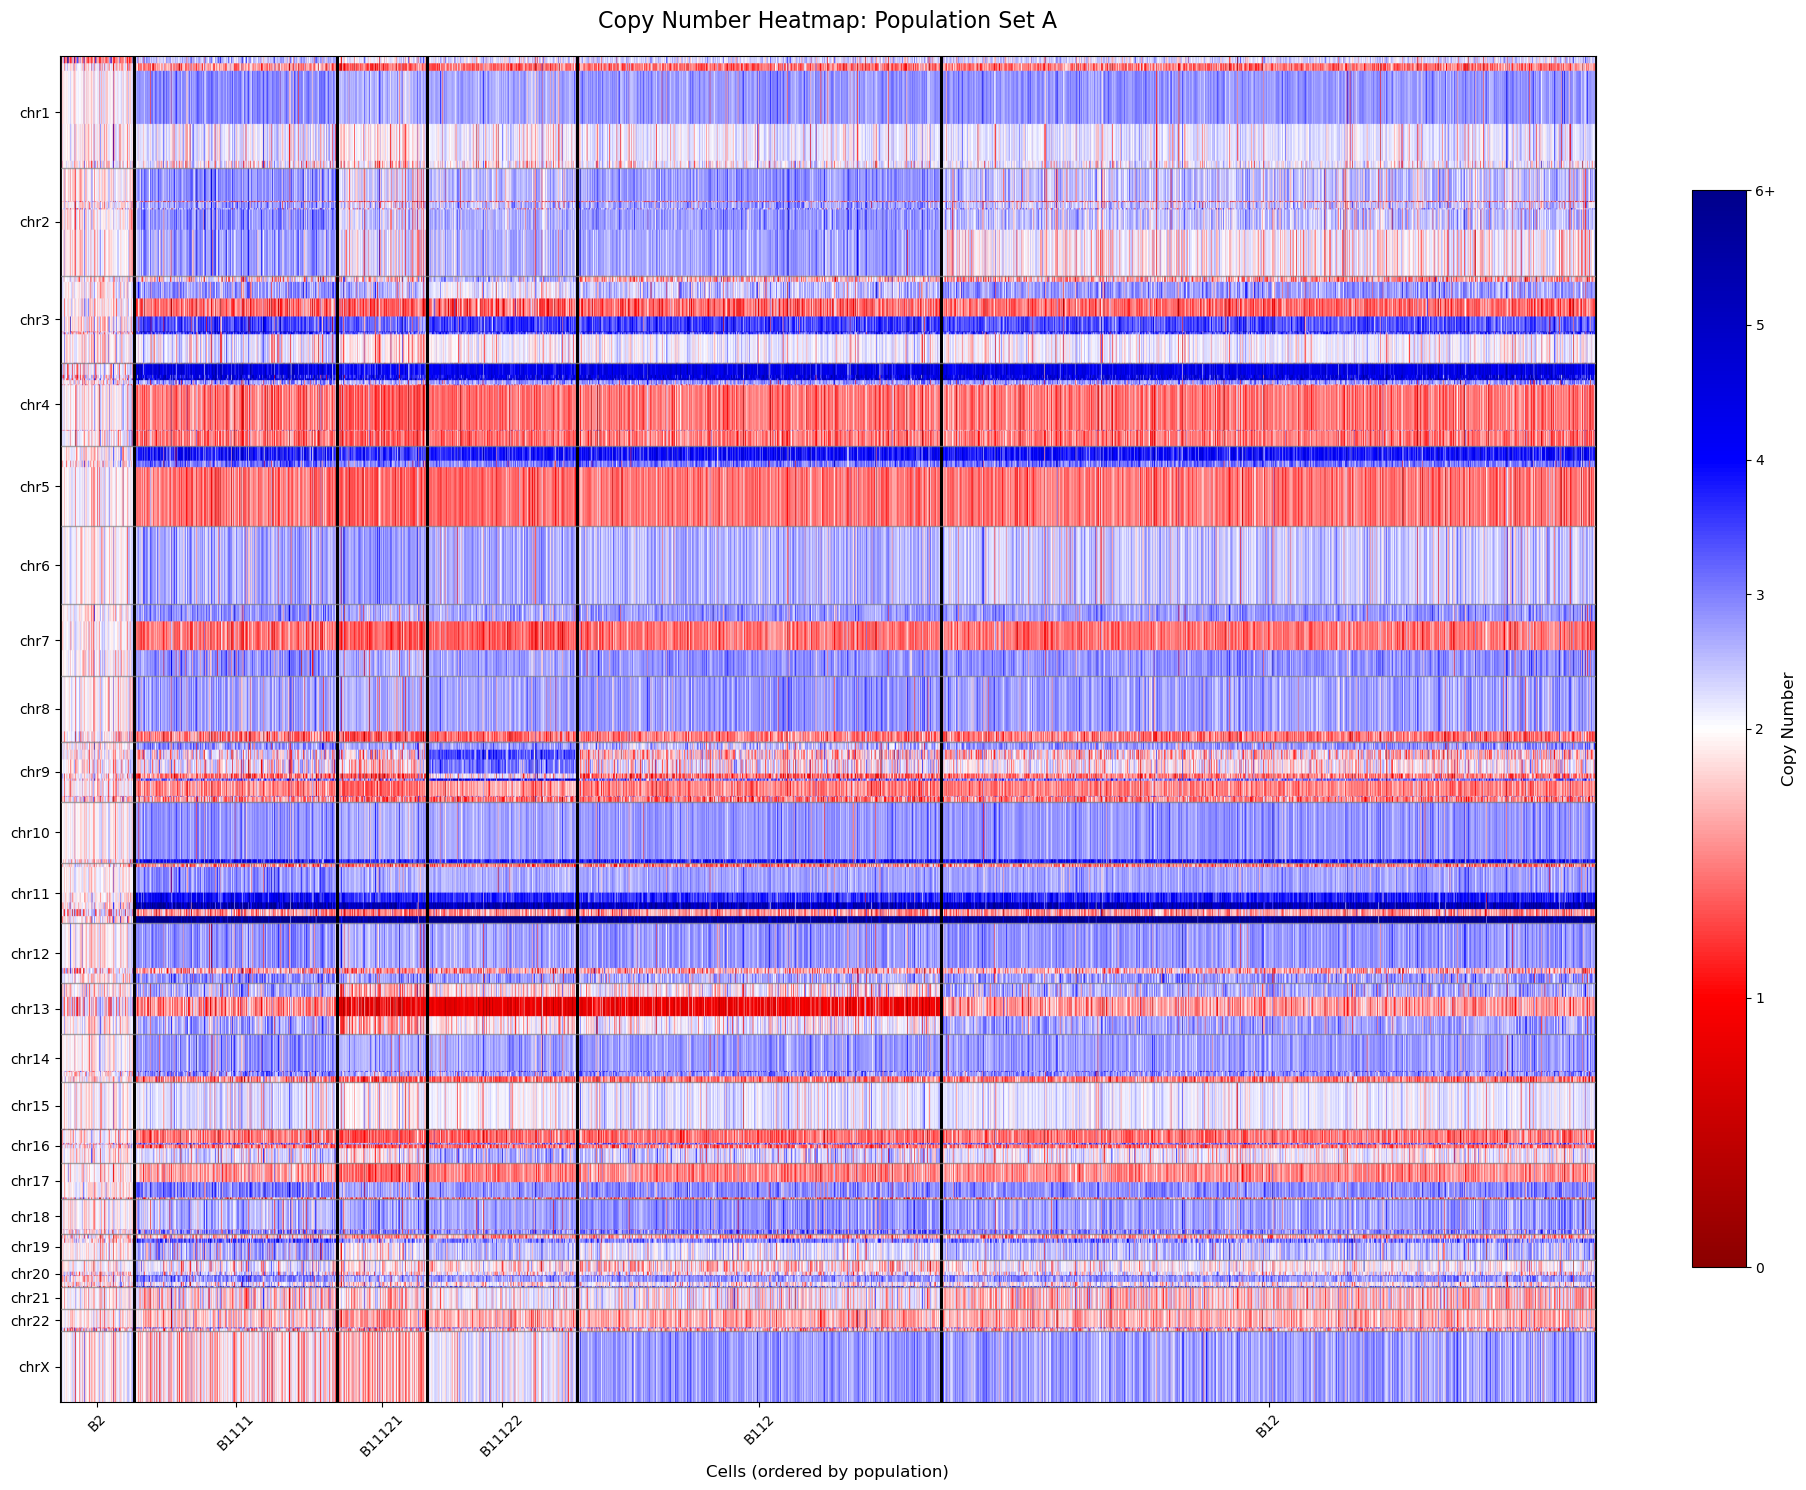

In [110]:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)